<div style="color:white;
           display:fill;
           border-radius:10px;
           background-color: #35bdb3;
           font-size:110%;
           font-family:Verdana;
           letter-spacing:0.5px">

<h1 style="padding: 35px; color:white; text-align:center; font-family:serif"><b>Predicting used car prices in India</b></h1>
</div>

![](http://blog.quikr.com/wp-content/uploads/2016/06/buy-second-hand-car-transfer-documents.jpg)

<h3 style="font-family:serif"><b> Importing the required libraries</b></h3>

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np 
import pandas as pd 

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, cross_val_score

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import mean_absolute_error

<h3 style="font-family:serif"><b> Reading the dataset </b></h3>

In [2]:
import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

/kaggle/input/used-cars-dataset-from-cardekhocom/Cardekho_Extract.csv
/kaggle/input/used-cars-dataset-from-cardekhocom/cardekho_updated.csv
/kaggle/input/used-cars-dataset-from-cardekhocom/cardekho_imputated.csv


In [3]:
data = pd.read_csv('/kaggle/input/used-cars-dataset-from-cardekhocom/cardekho_updated.csv')
print(f'''number of rows - {data.shape[0]}
number of columns - {data.shape[1]}''')

number of rows - 19974
number of columns - 13


In [4]:
data.head()

,full_name,selling_price,new_price,year,seller_type,km_driven,owner_type,fuel_type,transmission_type,mileage,engine,max_power,seats
0,Maruti Alto Std,1.2 Lakh*,NaN,2012,Individual,"1,20,000 kms",First Owner,Petrol,Manual,Mileage19.7 kmpl,Engine796 CC,Max Power46.3 bhp,Seats5
1,Hyundai Grand i10 Asta,5.5 Lakh*,New Car (On-Road Price) : Rs.7.11-7.48 Lakh*,2016,Individual,"20,000 kms",First Owner,Petrol,Manual,Mileage18.9 kmpl,Engine1197 CC,Max Power82 bhp,Seats5
2,Hyundai i20 Asta,2.15 Lakh*,NaN,2010,Individual,"60,000 kms",First Owner,Petrol,Manual,Mileage17.0 kmpl,Engine1197 CC,Max Power80 bhp,Seats5
3,Maruti Alto K10 2010-2014 VXI,2.26 Lakh*,NaN,2012,Individual,"37,000 kms",First Owner,Petrol,Manual,Mileage20.92 kmpl,Engine998 CC,Max Power67.1 bhp,Seats5
4,Ford Ecosport 2015-2021 1.5 TDCi Titanium BSIV,5.7 Lakh*,New Car (On-Road Price) : Rs.10.14-13.79 Lakh*,2015,Dealer,"30,000 kms",First Owner,Diesel,Manual,Mileage22.77 kmpl,Engine1498 CC,Max Power98.59 bhp,Seats5


<h3 style="font-family:serif"><b>Checking NaN values</b></h3>

In [5]:
def null_count():
    return pd.DataFrame({'features': data.columns,
                'dtypes': data.dtypes.values,
                'NaN count': data.isnull().sum().values,
                'NaN percentage': data.isnull().sum().values/data.shape[0]}).style.background_gradient(cmap='Blues',low=0.1,high=0.01)
null_count()

,features,dtypes,NaN count,NaN percentage
0,full_name,object,0,0.000000
1,selling_price,object,0,0.000000
2,new_price,object,10410,0.521178
3,year,int64,0,0.000000
4,seller_type,object,0,0.000000
5,km_driven,object,0,0.000000
6,owner_type,object,0,0.000000
7,fuel_type,object,0,0.000000
8,transmission_type,object,0,0.000000
9,mileage,object,160,0.008010


<div style="color:white;
           display:fill;
           border-radius:10px;
           background-color: #35bdb3;
           font-size:110%;
           font-family:Verdana;
           letter-spacing:0.5px">

<h1 style="padding: 20px; color:white; text-align:center; font-family:serif"><b>Cleaning the dataset</b></h1>
</div>

<h3 style="font-family:serif"><b>Cleaning selling price column</b></h3>
<p>selling price has different values such as "5.5 Lakh*", "2.3 Cr*" and "95,000*" which is of data type object, gettting only the numerical value and multipling by suffix value lakhs, cr... eg(5.5 Lakh*: 500000, 2.3Cr*: 23000000, 95,000*: 95000) </p>

In [6]:
for i in range(data.shape[0]):
    try:
        price = float(data['selling_price'][i].split(' ')[0])
        digit = data['selling_price'][i].split(' ')[1]
        if digit == 'Lakh*':
            price = price * 100000
            data['selling_price'][i] = price
        elif digit == 'Cr*':
            price = price * 10000000
            data['selling_price'][i] = price
    except:
        price = data['selling_price'][i][:-1]
        price = price.replace(',', '')
        data['selling_price'][i] = float(price)

<h3 style="font-family:serif"><b>Cleaning kilometer driven, Mileage, Engine, Maxpower and Seats columns</b></h3>
<p> km_driven, mileage, engine, max_power and seats have values like "120,000 kms", "Mileage19.7 kmpl", "Engine796CC", "Max Power46.3 bhp" and "seats5", getting only the numerical values from those strings. eg (km_driven: 120000, mileage: 19.7, engine:796, max_power: 46.3, seats: 5)</p>

In [7]:
# kilometer driven
data['km_driven'] = data['km_driven'].str.split(' ', n=1, expand=True)[0]
data['km_driven'] = data['km_driven'].str.replace(',','')
# Mileage
data['mileage'] = data['mileage'].str.split(' ', expand=True)[0].str.split('e', expand=True)[2]
# Engine
data['engine'] = data['engine'].str.split(' ', expand=True)[0].str.split('e',expand=True)[1]
# Max Power
data['max_power'] = data['max_power'].str.split(' ', expand=True)[1].str.split('r',expand=True)[1]
# Seats 
data['seats'] = data['seats'].str.split('s', expand=True)[1]

<h3 style="font-family:serif"><b>Changing the data types of the columns</b></h3>
<p>changing the data types of the feaures such as selling_price, km_driven, mileage, engine, max_power, seats to int/float</p>

In [8]:
cols = ['selling_price', 'km_driven', 'mileage', 'engine', 'max_power', 'seats']

for col in cols:
    try:
        data[col] = data[col].astype(int)
    except:
        data[col] = data[col].astype(float)

<h3 style="font-family:serif"><b>Creating new feature Company</b></h3>
<p> creating a new feature "company" from full_name by getting the first word which is actually the cars company name, "Ford Ecosport 2015-2021 1.5 TDCi Titanium BSIV" this car model belongs to Ford company</p>

In [9]:
# creating new feature company instead of full name
data['company'] = data['full_name'].str.split(' ', expand=True)[0]

<h3 style="font-family:serif"><b>Droping unwanted columns</b></h3>
<p>Droping "new_price" column which has more the 50 percent missing values, "full_name" because I created company column for better analysis and "owner_type" for having only one value which doesn't provide any information.</p>


In [10]:
data.drop(columns=['new_price','full_name','owner_type'], axis=1, inplace=True)
data.head()

,selling_price,year,seller_type,km_driven,fuel_type,transmission_type,mileage,engine,max_power,seats,company
0,120000,2012,Individual,120000,Petrol,Manual,19.70,796.0,46.30,5.0,Maruti
1,550000,2016,Individual,20000,Petrol,Manual,18.90,1197.0,82.00,5.0,Hyundai
2,215000,2010,Individual,60000,Petrol,Manual,17.00,1197.0,80.00,5.0,Hyundai
3,225999,2012,Individual,37000,Petrol,Manual,20.92,998.0,67.10,5.0,Maruti
4,570000,2015,Dealer,30000,Diesel,Manual,22.77,1498.0,98.59,5.0,Ford


<div style="color:white;
           display:fill;
           border-radius:10px;
           background-color: #35bdb3;
           font-size:110%;
           font-family:Verdana;
           letter-spacing:0.5px">

<h1 style="padding: 20px; color:white; text-align:center; font-family:serif"><b>Exploratory data analysis</b></h1>
</div>

<h3 style="font-family:serif"><b>Basic statistic on numerical features</b></h3>

In [11]:
data.describe().T

,count,mean,std,min,25%,50%,75%,max
selling_price,19974.0,739294.432612,910400.116520,25000.0,340000.00,520000.0,785000.00,39500000.0
year,19974.0,2014.526134,3.248791,1991.0,2013.00,2015.0,2017.00,2021.0
km_driven,19974.0,58238.894663,51727.595500,100.0,31114.00,52000.0,74000.00,3800000.0
mileage,19814.0,19.503637,4.298090,4.0,16.95,19.3,22.32,120.0
engine,19864.0,1477.805981,519.843056,72.0,1197.00,1248.0,1582.00,6752.0
max_power,19637.0,99.448762,43.784904,25.4,73.94,86.8,114.00,626.0
seats,19887.0,5.319807,0.837676,2.0,5.00,5.0,5.00,14.0


<h3 style="font-family:serif"><b>Basic statistics on categorical features</b></h3>

In [12]:
data.describe(include='O')

,seller_type,fuel_type,transmission_type,company
count,19974,19974,19974,19974
unique,3,5,2,42
top,Dealer,Diesel,Manual,Maruti
freq,11970,9815,16025,5648


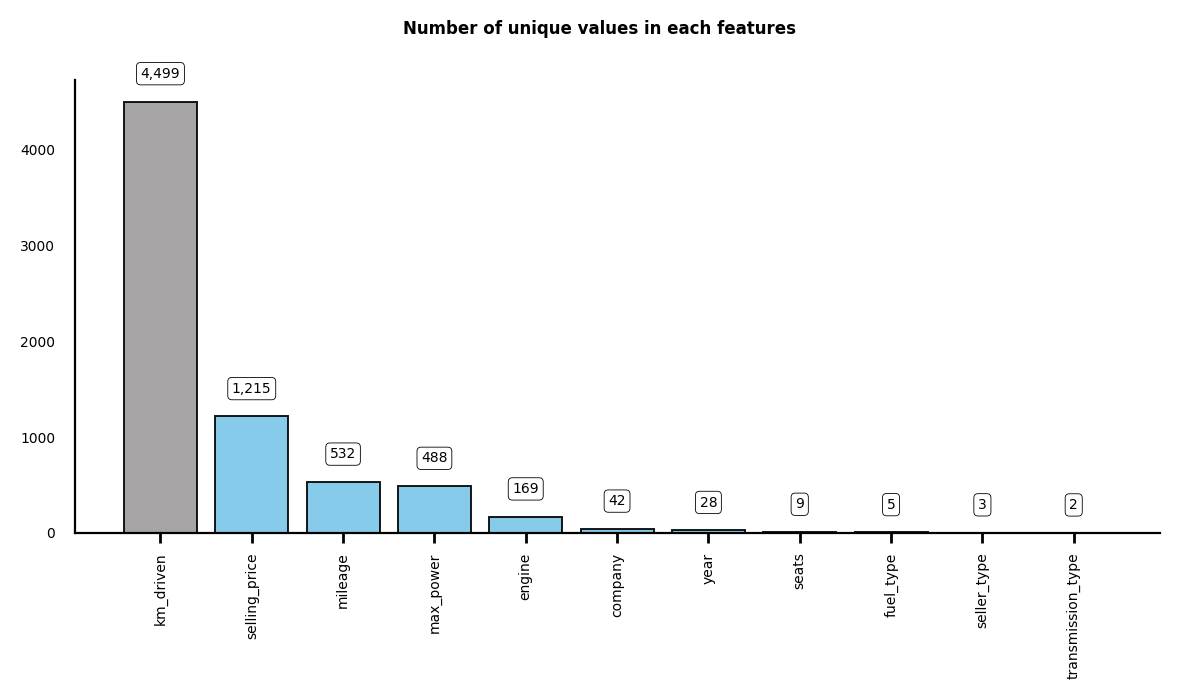

In [13]:
x = data.nunique().sort_values(ascending=False).index
y = data.nunique().sort_values(ascending=False).values

plt.rcParams['figure.dpi'] = 200
fig = plt.figure(figsize=(7,3))
gs = fig.add_gridspec(1,1)
ax0 = fig.add_subplot(gs[0,0])
for i in ['top', 'right']:
    ax0.spines[i].set_visible(False)
    
colormap = ['#79c6e8' for i in range(data.shape[1])]
colormap[0] = '#9c9a9a'

ax0.bar(x=x, height=y, edgecolor='k', linewidth=0.7, color=colormap, alpha=0.9)
ax0.tick_params(axis='x',labelsize=5, rotation=90, width=1)
ax0.tick_params(axis='y', labelsize=5, left=False)
fig.suptitle(t='Number of unique values in each features', fontsize=6, weight='bold')

for p in ax0.patches:
    value = f'{p.get_height():,.0f}'
    x = p.get_x() + p.get_width() / 2
    y = p.get_y() + p.get_height()+290
    ax0.text(x, y, value, ha='center', va='center', fontsize=5, 
            bbox=dict(facecolor='white', edgecolor='black', boxstyle='round', linewidth=0.3))
plt.show()


<h3 style="font-family:serif"><b>Univariate analysis in numerical features</b></h3>

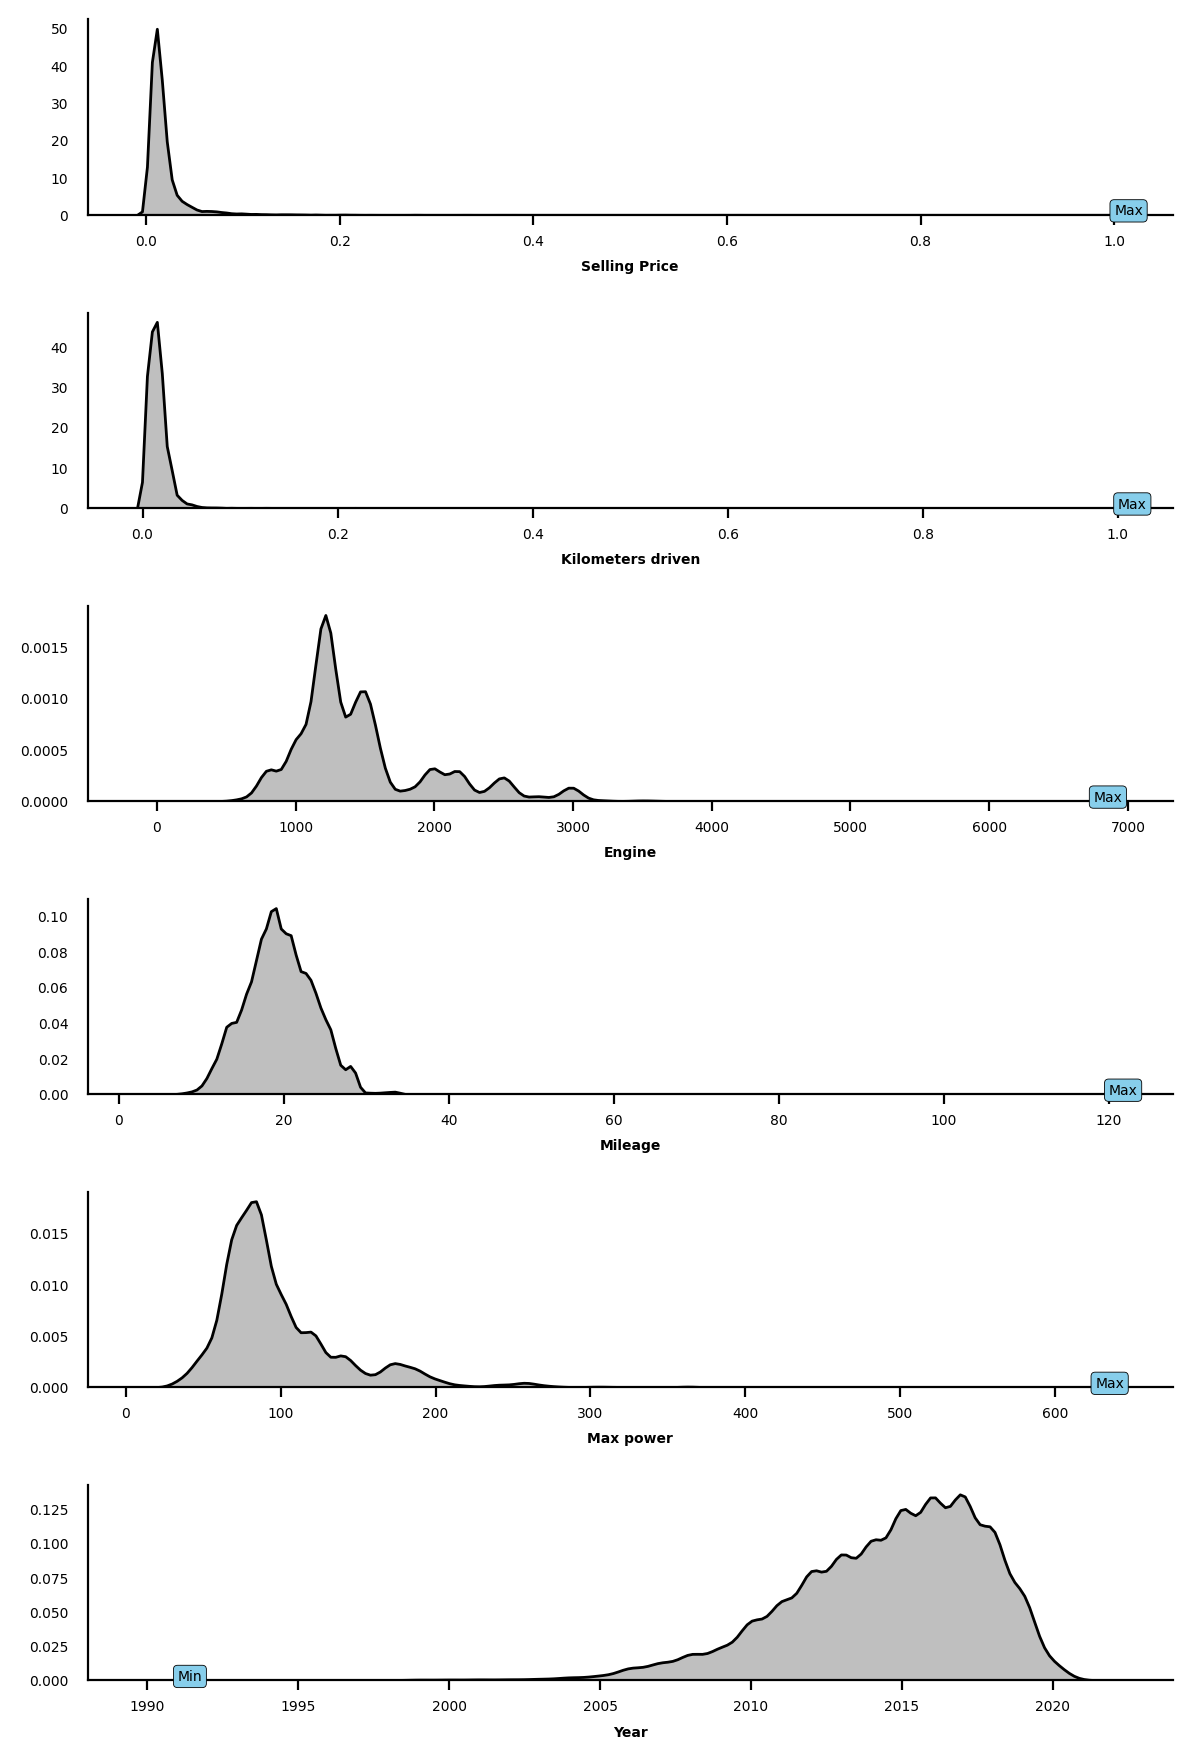

In [14]:
plt.rcParams['figure.dpi'] = 200
fig = plt.figure(figsize=(7,11))
# fig.suptitle(t='Distribution of numerical features', fontsize=6, weight='bold')
gs = fig.add_gridspec(6,1)
gs.update(hspace=0.5)

mi=data.selling_price.min()
ma=data.selling_price.max()
price = (data.selling_price-mi)/(ma-mi)

ax0 = fig.add_subplot(gs[0,0])
ax0_sns = sns.kdeplot(x=price, shade=True, color='k')
ax0.text(x=price.max(), y=0, s='Max', fontsize=5, bbox=dict(facecolor='skyblue',linewidth=0.3,boxstyle='round'))
ax0_sns.tick_params(axis='both', labelsize=5, left=False)
ax0_sns.set_xlabel('Selling Price', fontsize=5, weight='bold')
ax0_sns.set_ylabel(None)

mi=data.km_driven.min()
ma=data.km_driven.max()
driven = (data.km_driven-mi)/(ma-mi)
ax1 = fig.add_subplot(gs[1,0])
ax1_sns = sns.kdeplot(x=driven, shade=True, color='k')
ax1.text(x=driven.max(), y=0, s='Max', fontsize=5, bbox=dict(facecolor='skyblue',linewidth=0.3,boxstyle='round'))
ax1_sns.tick_params(axis='both', labelsize=5, left=False)
ax1_sns.set_xlabel('Kilometers driven', fontsize=5, weight='bold')
ax1_sns.set_ylabel(None)

ax2 = fig.add_subplot(gs[2,0])
ax2_sns = sns.kdeplot(data=data,x='engine', shade=True, color='k')
ax2.text(x=data.engine.max(), y=0, s='Max', fontsize=5, bbox=dict(facecolor='skyblue',linewidth=0.3,boxstyle='round'))
ax2_sns.tick_params(axis='both', labelsize=5, left=False)
ax2_sns.set_xlabel('Engine', fontsize=5, weight='bold')
ax2_sns.set_ylabel(None)

ax3 = fig.add_subplot(gs[3,0])
ax3_sns = sns.kdeplot(data=data,x='mileage', shade=True, color='k')
ax3.text(x=data.mileage.max(), y=0, s='Max', fontsize=5, bbox=dict(facecolor='skyblue',linewidth=0.3,boxstyle='round'))
ax3_sns.tick_params(axis='both', labelsize=5, left=False)
ax3_sns.set_xlabel('Mileage', fontsize=5, weight='bold')
ax3_sns.set_ylabel(None)

ax4 = fig.add_subplot(gs[4,0])
ax4_sns = sns.kdeplot(data=data,x='max_power', shade=True, color='k')
ax4.text(x=data.max_power.max(), y=0, s='Max', fontsize=5, bbox=dict(facecolor='skyblue',linewidth=0.3,boxstyle='round'))
ax4_sns.tick_params(axis='both', labelsize=5, left=False)
ax4_sns.set_xlabel('Max power', fontsize=5, weight='bold')
ax4_sns.set_ylabel(None)

ax5 = fig.add_subplot(gs[5,0])
ax5_sns = sns.kdeplot(data=data,x='year', shade=True, color='k')
ax5.text(x=data.year.min(), y=0, s='Min', fontsize=5, bbox=dict(facecolor='skyblue',linewidth=0.3,boxstyle='round'))
ax5_sns.tick_params(axis='both', labelsize=5, left=False)
ax5_sns.set_xlabel('Year', fontsize=5, weight='bold')
ax5_sns.set_ylabel(None)

sns.despine()
plt.show()

<h3 style="font-family:serif"><b>Univariate Analysis in categorical features</b></h3>

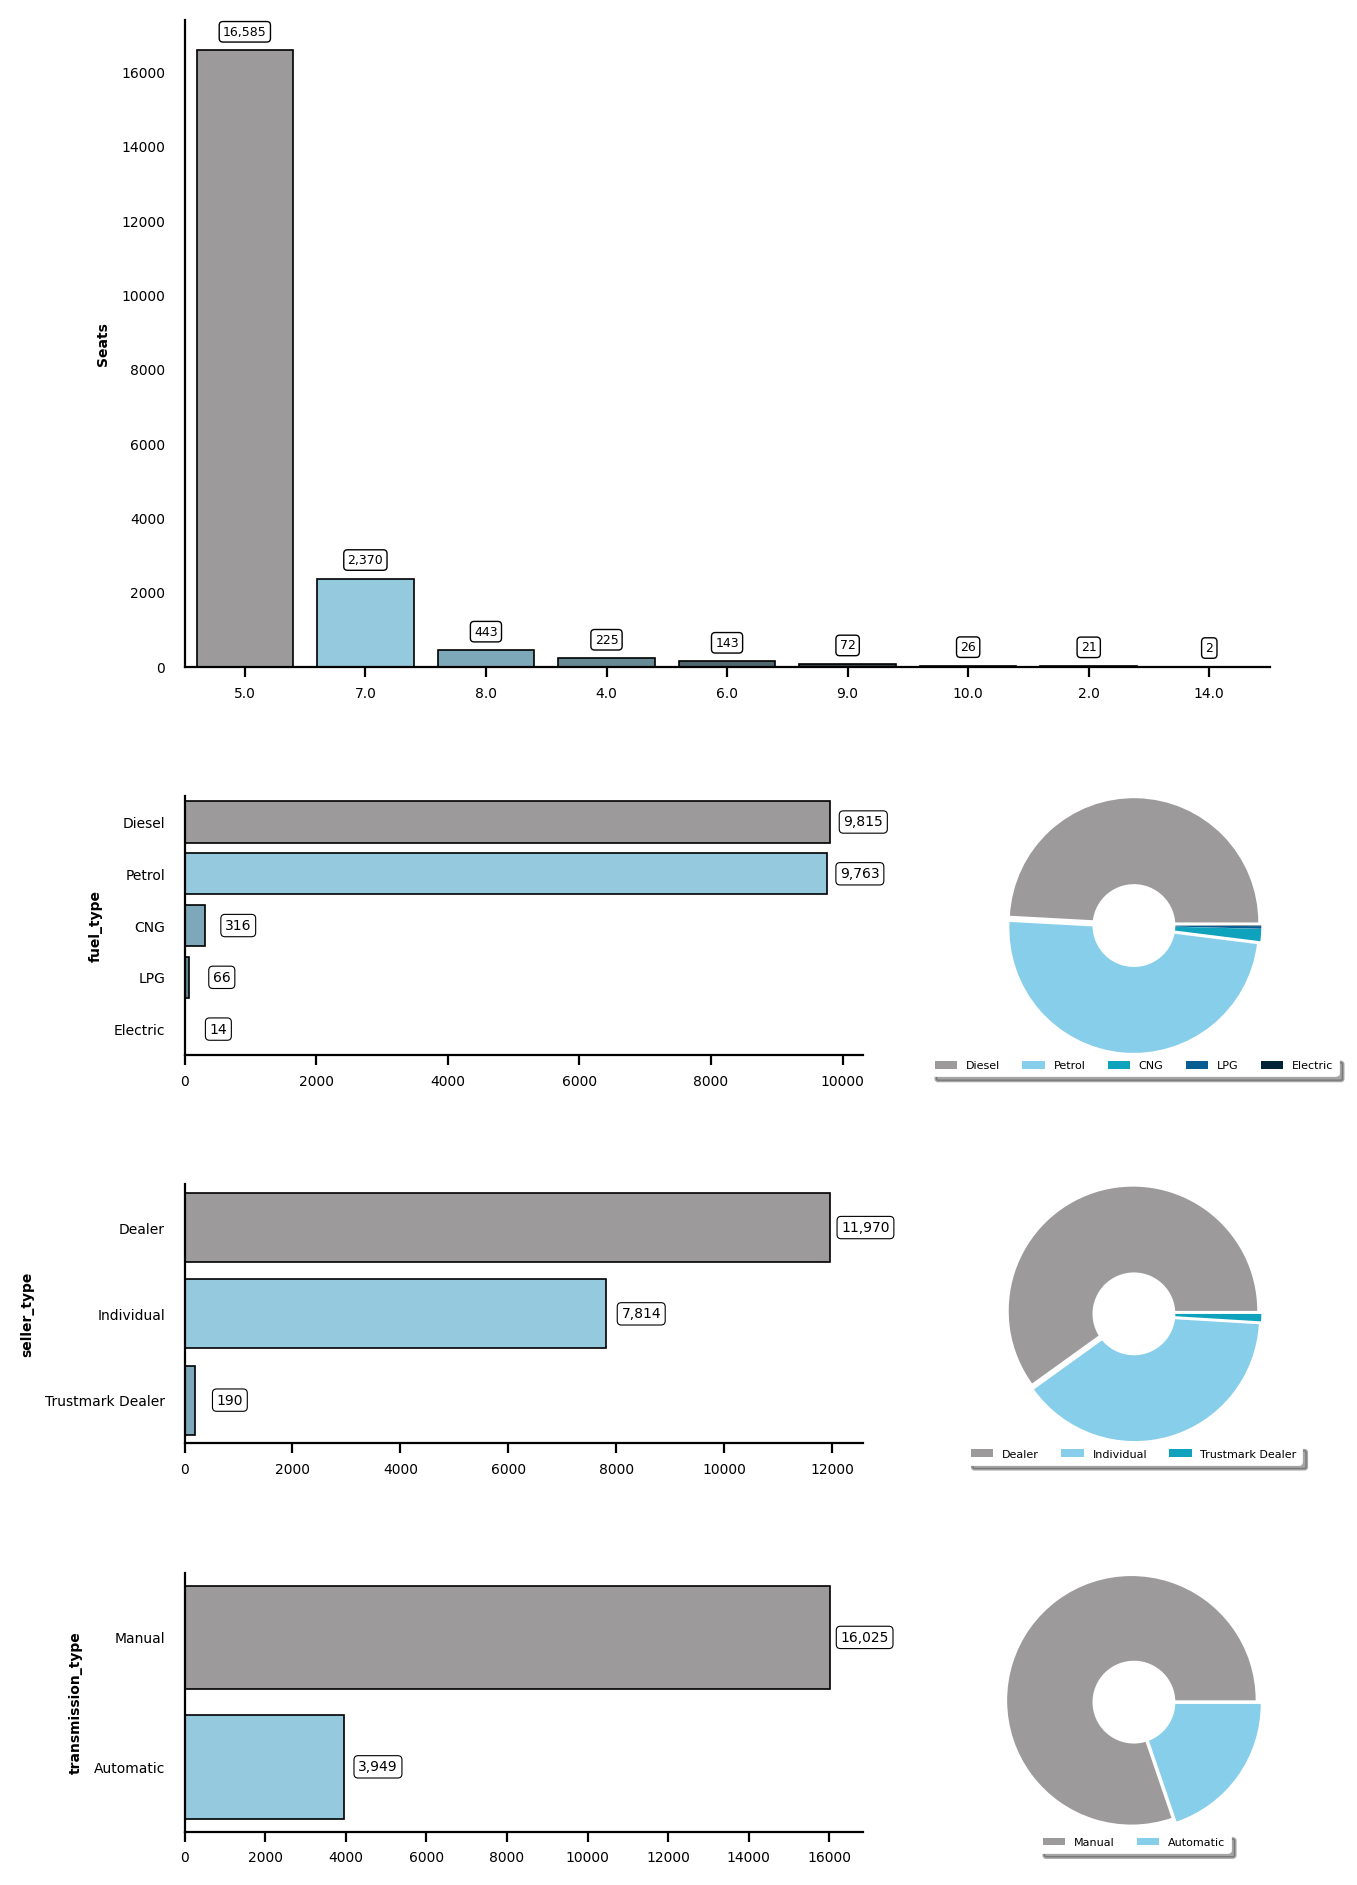

In [15]:
fig = plt.figure(figsize=(7,12))
gs = fig.add_gridspec(5,3)
gs.update(hspace=0.5, wspace=0.5)

pal = sns.dark_palette('skyblue', reverse=True)
pal.insert(0, '#9c9a9a')
# Row 1 ----------------------------------------------------------------------------------------------------------
# Countplot
ax0 = fig.add_subplot(gs[0:2,0:3])
ax0_s = sns.countplot(data=data,
                      x='seats', 
                      palette=pal, 
                      edgecolor='k', 
                      linewidth=0.6, 
                      order=[i for i in data.seats.value_counts().index])
ax0_s.tick_params(labelsize=5, left=False)
ax0_s.set_xlabel(None)
ax0_s.set_ylabel(ylabel='Seats', fontsize=5, weight='bold')

for p in ax0_s.patches:
    value = f"{p.get_height():,.0f}"
    x = p.get_x() + p.get_width()/2
    y = p.get_y() + p.get_height()+500
    ax0.text(x, y, value, fontsize=4.5, ha='center', va='center', 
             bbox=dict(facecolor='white', edgecolor='k', boxstyle='round', linewidth=0.5))
    
# Row 2 ----------------------------------------------------------------------------------------------------------- 
# Countplot-----------
ax1 = fig.add_subplot(gs[2,0:2])
ax1_s = sns.countplot(data=data, y='fuel_type', 
                      palette=pal, edgecolor='k', linewidth=0.6, 
                      order=[i for i in data.fuel_type.value_counts().index])
ax1_s.tick_params(labelsize=5, left=False)
ax1_s.set_xlabel(None)
ax1_s.set_ylabel(ylabel='fuel_type', fontsize=5, weight='bold')
for p in ax1_s.patches:
    value = f"{p.get_width():,.0f}"
    x = p.get_x() + p.get_width()+500
    y = p.get_y() + p.get_height()/2
    ax1.text(x, y, value, fontsize=5, ha='center', va='center', 
             bbox=dict(facecolor='white', edgecolor='k', boxstyle='round', linewidth=0.4))
# Pie plot------------ 
ax11 = fig.add_subplot(gs[2,2])
ax11.pie(x = data.fuel_type.value_counts().values,
        colors=['#9c9a9a','skyblue','#0fa2bd','#075c91','#012338'],
        explode = [0.03 for i in range(data.fuel_type.nunique())],
        radius=1.2,
        textprops=dict(fontsize=5))
ax11.add_artist(plt.Circle((0,0),0.4,fc='white'))
ax11.legend(labels = data.fuel_type.value_counts().index, 
            ncol=5, fontsize=4,edgecolor='white', shadow=True, loc='lower center',bbox_to_anchor=(0.5,-0.1))

# Row 3 ------------------------------------------------------------------------------------------------------------
# Countplot-----------
ax2 = fig.add_subplot(gs[3,0:2])
ax2_s = sns.countplot(data=data, y='seller_type', 
                      palette=pal, edgecolor='k', linewidth=0.6, 
                      order=[i for i in data.seller_type.value_counts().index])
ax2_s.tick_params(labelsize=5, left=False)
ax2_s.set_xlabel(None)
ax2_s.set_ylabel(ylabel='seller_type', fontsize=5, weight='bold')
for p in ax2_s.patches:
    value = f"{p.get_width():,.0f}"
    x = p.get_x() + p.get_width()+650
    y = p.get_y() + p.get_height()/2
    ax2.text(x, y, value, fontsize=5, ha='center', va='center', 
             bbox=dict(facecolor='white', edgecolor='k', boxstyle='round', linewidth=0.4))
# Pie plot------------  
ax21 = fig.add_subplot(gs[3,2])
ax21.pie(x = data.seller_type.value_counts().values,
        colors=['#9c9a9a','skyblue','#0fa2bd','#075c91','#012338'],
        explode = [0.03 for i in range(data.seller_type.nunique())],
        textprops=dict(fontsize=5),
        radius=1.2)
ax21.add_artist(plt.Circle((0,0),0.4,fc='white'))
ax21.legend(labels = data.seller_type.value_counts().index, 
            ncol=5, fontsize=4,edgecolor='white', shadow=True, loc='lower center',bbox_to_anchor=(0.5,-0.1))

# Row 4 ------------------------------------------------------------------------------------------------------------
# Countplot-----------
ax3 = fig.add_subplot(gs[4,0:2])
ax3_s = sns.countplot(data=data, y='transmission_type', 
                      palette=pal, edgecolor='k', linewidth=0.6, 
                      order=[i for i in data.transmission_type.value_counts().index])
ax3_s.tick_params(labelsize=5, left=False)
ax3_s.set_xlabel(None)
ax3_s.set_ylabel(ylabel='transmission_type', fontsize=5, weight='bold')
for p in ax3_s.patches:
    value = f"{p.get_width():,.0f}"
    x = p.get_x() + p.get_width()+850
    y = p.get_y() + p.get_height()/2
    ax3.text(x, y, value, fontsize=5, ha='center', va='center', 
             bbox=dict(facecolor='white', edgecolor='k', boxstyle='round', linewidth=0.4))
# Pie plot------------  
ax31 = fig.add_subplot(gs[4,2])
ax31.pie(x = data.transmission_type.value_counts().values,
        colors=['#9c9a9a','skyblue','#0fa2bd','#075c91','#012338'],
        explode = [0.03 for i in range(data.transmission_type.nunique())],
        textprops=dict(fontsize=5),
        radius=1.2)
ax31.add_artist(plt.Circle((0,0),0.4,fc='white'))
ax31.legend(labels = data.transmission_type.value_counts().index, 
            ncol=5, edgecolor='white',shadow=True, fontsize=4, loc='lower center',bbox_to_anchor=(0.5,-0.1))

sns.despine()
plt.show()

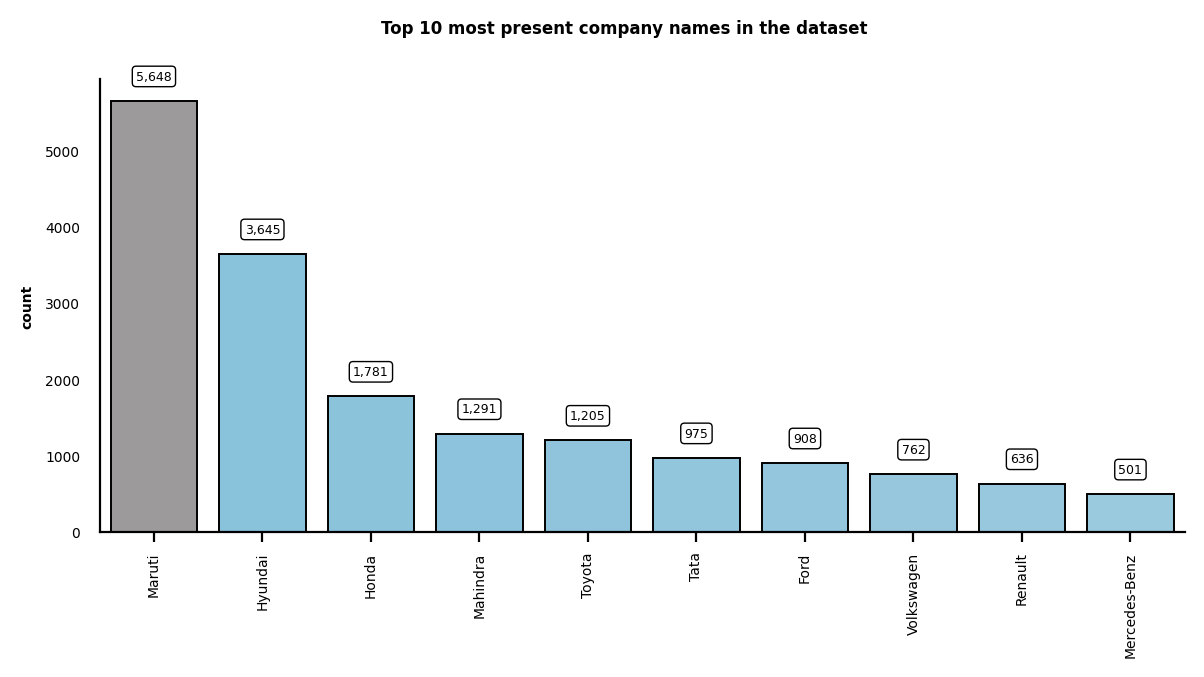

In [16]:
fig = plt.figure(figsize=(7,3))
gs = fig.add_gridspec(1,1)

cars = data.company.value_counts().head(10)
pal = sns.light_palette('#79c6e8', n_colors=50, reverse=True)
pal[0] = '#9c9a9a'
ax = fig.add_subplot(gs[0,0])
ax=sns.barplot(x=cars.index, y=cars.values, edgecolor='k', linewidth=0.7, palette=pal)
ax.tick_params(axis='x', labelsize=5, rotation=90)
ax.tick_params(axis='y', labelsize=5, left=False)
ax.set_ylabel(ylabel='count', fontsize=5, weight='bold')

for p in ax.patches:
    value = f'{p.get_height():,.0f}'
    x = p.get_x() + p.get_width()/2
    y = p.get_y() + p.get_height()+320
    ax.text(x=x, y=y, s=value, fontsize=4.5, ha='center', va='center',
           bbox=dict(fc='white', edgecolor='k', boxstyle='round', linewidth=0.5))
    
fig.suptitle(t='Top 10 most present company names in the dataset', fontsize='6', weight='bold')
sns.despine()
plt.show()

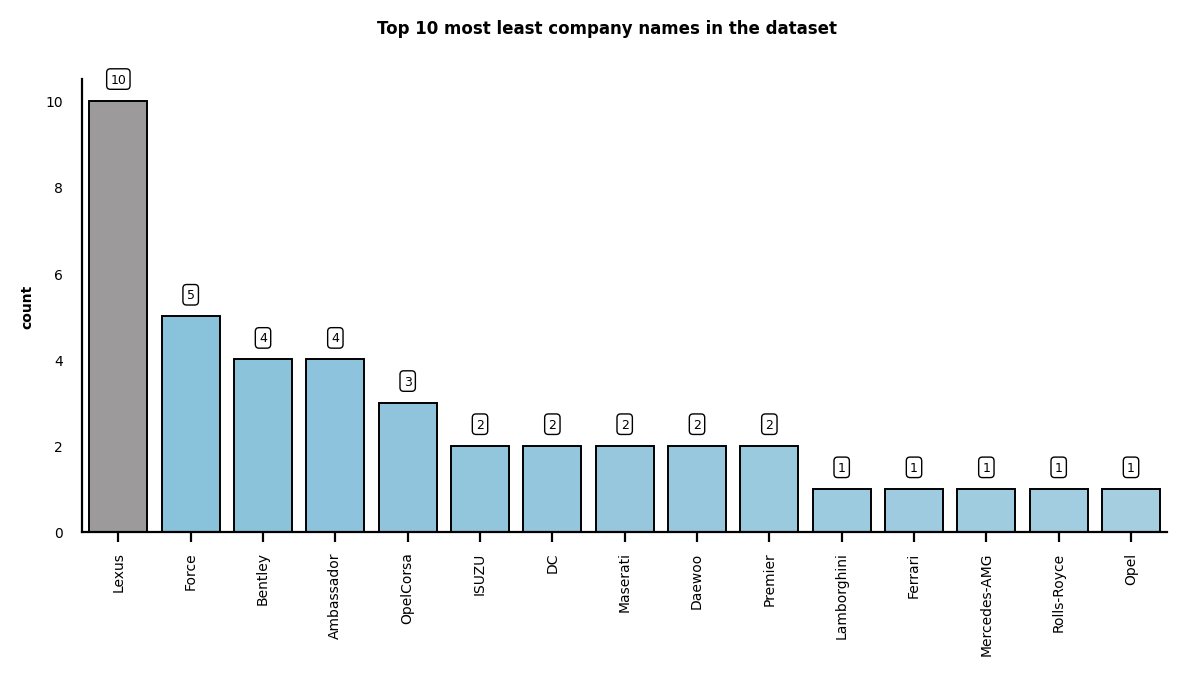

In [17]:
fig = plt.figure(figsize=(7,3))
gs = fig.add_gridspec(1,1)

cars = data.company.value_counts().tail(15)
pal = sns.light_palette('#79c6e8', n_colors=50, reverse=True)
pal[0] = '#9c9a9a'
ax = fig.add_subplot(gs[0,0])
ax=sns.barplot(x=cars.index, y=cars.values, edgecolor='k', linewidth=0.7, palette=pal)
ax.tick_params(axis='x', labelsize=5, rotation=90)
ax.tick_params(axis='y', labelsize=5, left=False)
ax.set_ylabel(ylabel='count', fontsize=5, weight='bold')

for p in ax.patches:
    value = f'{p.get_height():,.0f}'
    x = p.get_x() + p.get_width()/2
    y = p.get_y() + p.get_height()+0.5
    ax.text(x=x, y=y, s=value, fontsize=4.5, ha='center', va='center',
           bbox=dict(fc='white', edgecolor='k', boxstyle='round', linewidth=0.5))
    
fig.suptitle(t='Top 10 most least company names in the dataset', fontsize='6', weight='bold')
sns.despine()
plt.show()

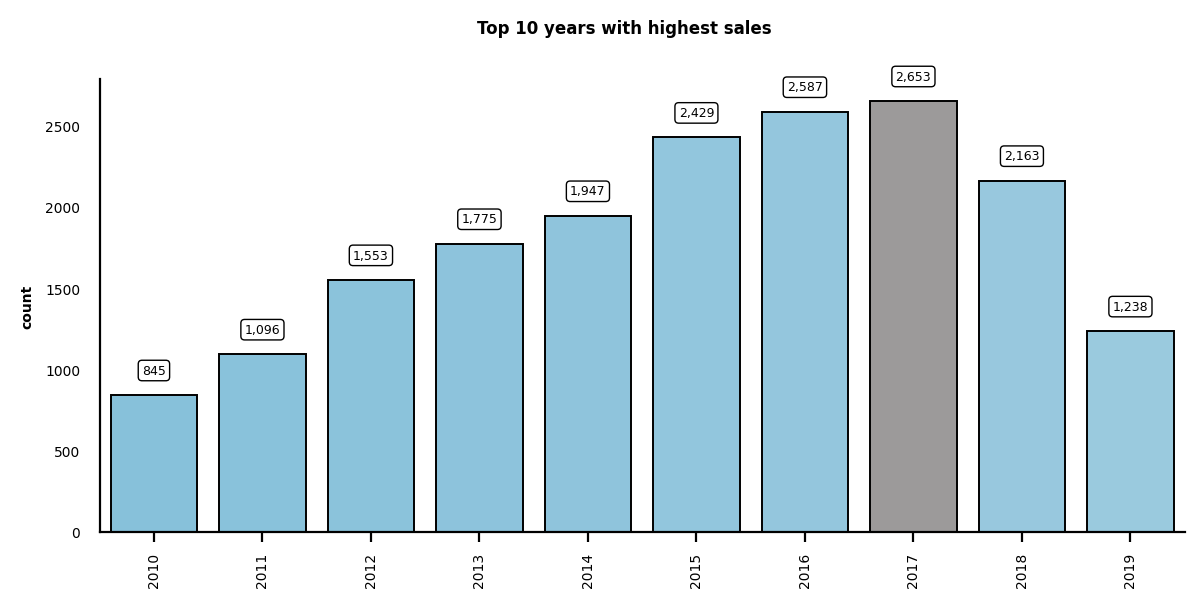

In [18]:
fig = plt.figure(figsize=(7,3))
gs = fig.add_gridspec(1,1)

cars = data.year.value_counts().head(10)
pal = sns.light_palette('#79c6e8', n_colors=50, reverse=True)
pal[7] = '#9c9a9a'
ax = fig.add_subplot(gs[0,0])
ax=sns.barplot(x=cars.index, y=cars.values, edgecolor='k', linewidth=0.7, palette=pal)
ax.tick_params(axis='x', labelsize=5, rotation=90)
ax.tick_params(axis='y', labelsize=5, left=False)
ax.set_ylabel(ylabel='count', fontsize=5, weight='bold')

for p in ax.patches:
    value = f'{p.get_height():,.0f}'
    x = p.get_x() + p.get_width()/2
    y = p.get_y() + p.get_height()+150
    ax.text(x=x, y=y, s=value, fontsize=4.5, ha='center', va='center',
           bbox=dict(fc='white', edgecolor='k', boxstyle='round', linewidth=0.5))
    
fig.suptitle(t='Top 10 years with highest sales', fontsize='6', weight='bold')
sns.despine()
plt.show()

<h3 style="font-family:serif"><b>Bivariate Analysis </b></h3>

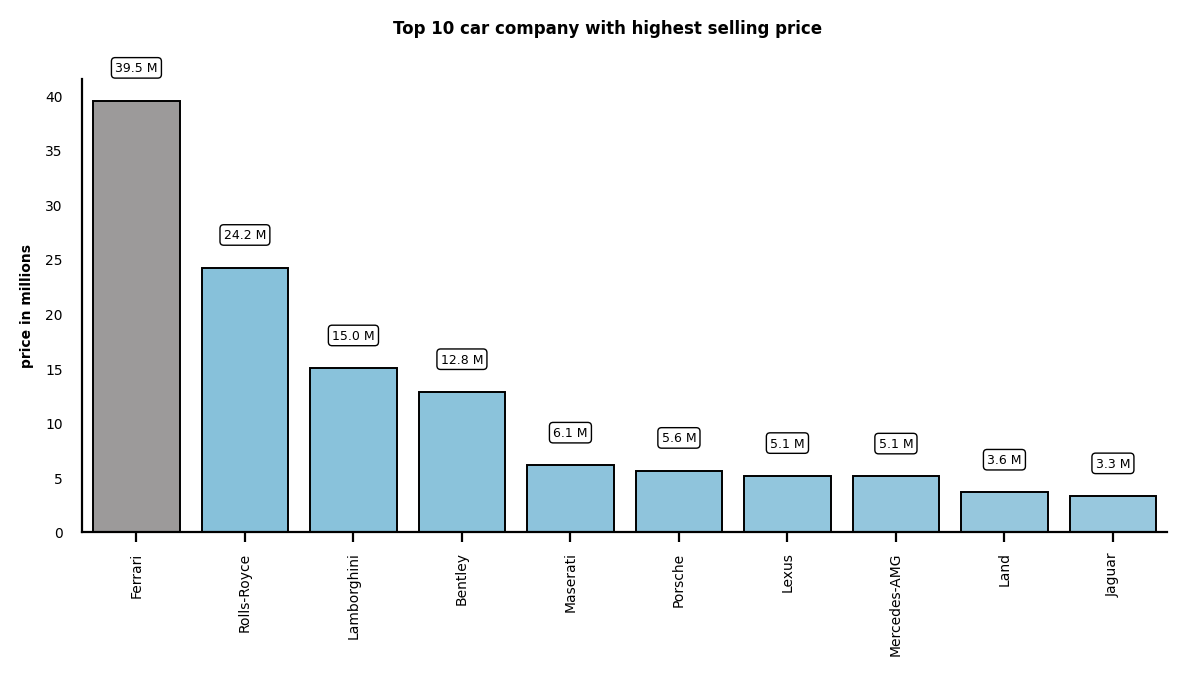

In [19]:
fig = plt.figure(figsize=(7,3))
gs = fig.add_gridspec(1,1)

pal = sns.light_palette('#79c6e8', reverse=True, n_colors=50)
pal.insert(0,'#9c9a9a')

cars = data.groupby('company')['selling_price'].mean().sort_values(ascending=False).head(10)/1000000
ax = fig.add_subplot(gs[0,0])
ax=sns.barplot(x=cars.index, y=cars.values, edgecolor='k', linewidth=0.7, palette=pal)
ax.tick_params(axis='x', labelsize=5, rotation=90)
ax.tick_params(axis='y', labelsize=5, left=False)
ax.set_xlabel(xlabel=None)
ax.set_ylabel(ylabel='price in millions', fontsize=5, weight='bold')
for p in ax.patches:
    value = f'{p.get_height():,.1f}' + ' M'
    x = p.get_x() + p.get_width()/2
    y = p.get_y() + p.get_height()+3
    ax.text(x=x, y=y, s=value, fontsize=4.5, ha='center', va='center',
           bbox=dict(fc='white', edgecolor='k', boxstyle='round', linewidth=0.5))
    
fig.suptitle(t='Top 10 car company with highest selling price', fontsize=6, weight='bold')
sns.despine()
plt.show()

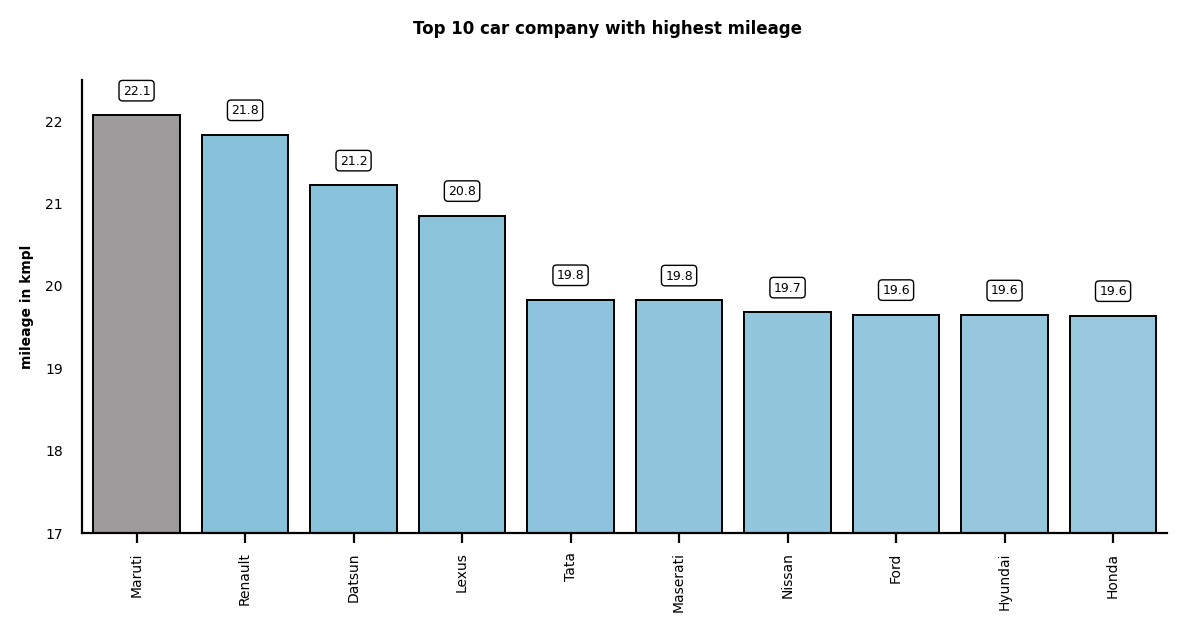

In [20]:
fig = plt.figure(figsize=(7,3))
gs = fig.add_gridspec(1,1)

pal = sns.light_palette('#79c6e8', reverse=True, n_colors=50)
pal.insert(0,'#9c9a9a')

cars = data.groupby('company')['mileage'].mean().sort_values(ascending=False).head(10)
ax = fig.add_subplot(gs[0,0])
ax=sns.barplot(x=cars.index, y=cars.values, edgecolor='k', linewidth=0.7, palette=pal)
ax.tick_params(axis='x', labelsize=5, rotation=90)
ax.tick_params(axis='y', labelsize=5, left=False)
ax.set_xlabel(xlabel=None)
ax.set_ylabel(ylabel='mileage in kmpl', fontsize=5, weight='bold')
ax.set_ylim(17,22.5)

for p in ax.patches:
    value = f'{p.get_height():,.1f}'
    x = p.get_x() + p.get_width()/2
    y = p.get_y() + p.get_height()+0.3
    ax.text(x=x, y=y, s=value, fontsize=4.5, ha='center', va='center',
           bbox=dict(fc='white', edgecolor='k', boxstyle='round', linewidth=0.5))
    
fig.suptitle(t='Top 10 car company with highest mileage', fontsize=6, weight='bold')
sns.despine()
plt.show()

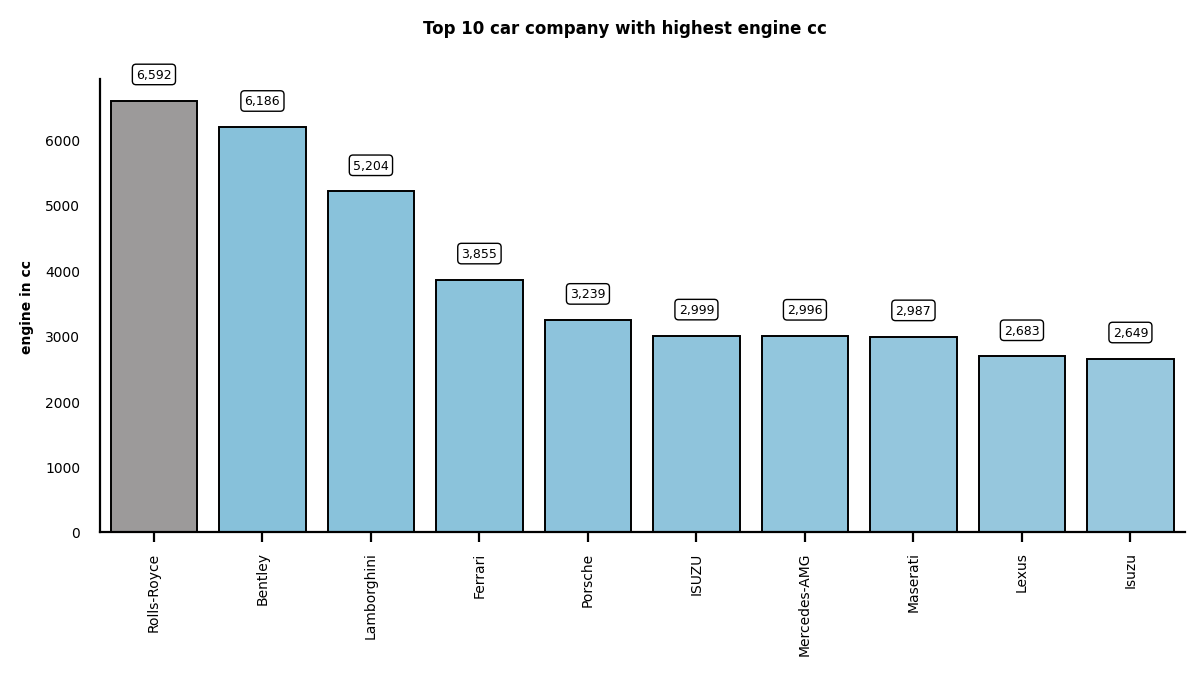

In [21]:
fig = plt.figure(figsize=(7,3))
gs = fig.add_gridspec(1,1)

pal = sns.light_palette('#79c6e8', reverse=True, n_colors=50)
pal.insert(0,'#9c9a9a')

cars = data.groupby('company')['engine'].mean().sort_values(ascending=False).head(10)
ax = fig.add_subplot(gs[0,0])
ax=sns.barplot(x=cars.index, y=cars.values, edgecolor='k', linewidth=0.7, palette=pal)
ax.tick_params(axis='x', labelsize=5, rotation=90)
ax.tick_params(axis='y', labelsize=5, left=False)
ax.set_xlabel(xlabel=None)
ax.set_ylabel(ylabel='engine in cc', fontsize=5, weight='bold')
for p in ax.patches:
    value = f'{p.get_height():,.0f}'
    x = p.get_x() + p.get_width()/2
    y = p.get_y() + p.get_height()+400
    ax.text(x=x, y=y, s=value, fontsize=4.5, ha='center', va='center',
           bbox=dict(fc='white', edgecolor='k', boxstyle='round', linewidth=0.5))
    
fig.suptitle(t='Top 10 car company with highest engine cc', fontsize=6, weight='bold')
sns.despine()
plt.show()

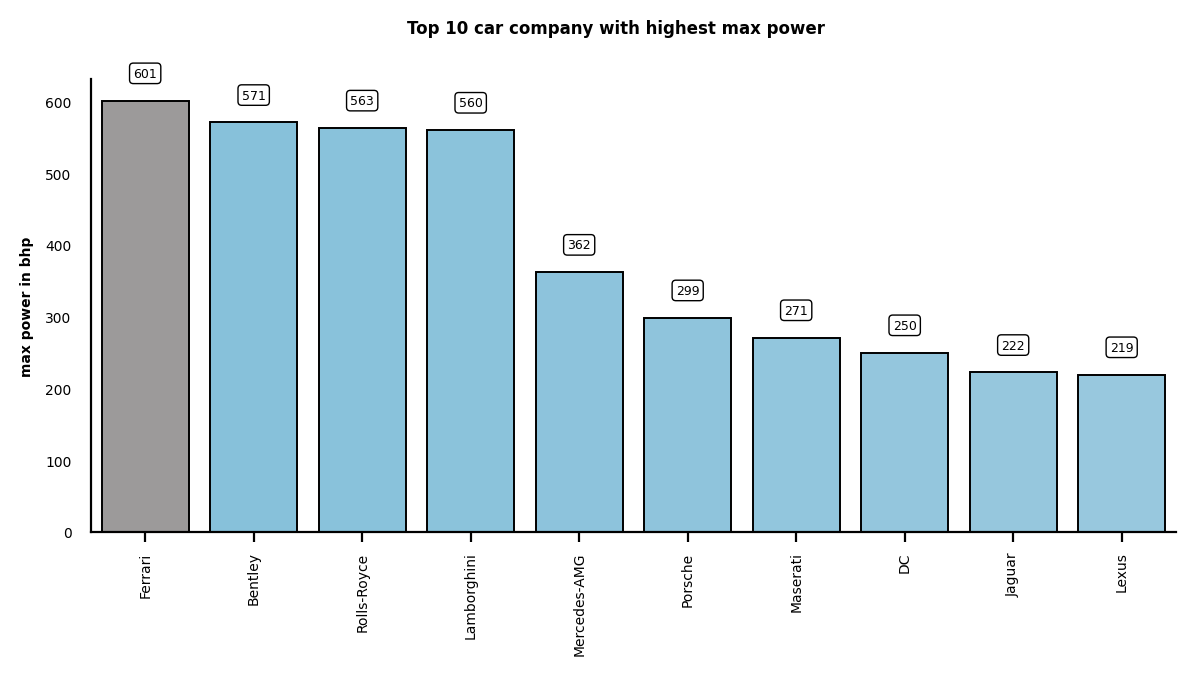

In [22]:
fig = plt.figure(figsize=(7,3))
gs = fig.add_gridspec(1,1)

pal = sns.light_palette('#79c6e8', reverse=True, n_colors=50)
pal.insert(0,'#9c9a9a')

cars = data.groupby('company')['max_power'].mean().sort_values(ascending=False).head(10)
color = ['skyblue' for i in range(15)]
color[0] = 'grey'
ax = fig.add_subplot(gs[0,0])
ax=sns.barplot(x=cars.index, y=cars.values, edgecolor='k', linewidth=0.7, palette=pal)
ax.tick_params(axis='x', labelsize=5, rotation=90)
ax.tick_params(axis='y', labelsize=5, left=False)
ax.set_xlabel(xlabel=None)
ax.set_ylabel(ylabel='max power in bhp', fontsize=5, weight='bold')
for p in ax.patches:
    value = f'{p.get_height():,.0f}'
    x = p.get_x() + p.get_width()/2
    y = p.get_y() + p.get_height()+38
    ax.text(x=x, y=y, s=value, fontsize=4.5, ha='center', va='center',
           bbox=dict(fc='white', edgecolor='k', boxstyle='round', linewidth=0.5))
    
fig.suptitle(t='Top 10 car company with highest max power', fontsize=6, weight='bold')
sns.despine()
plt.show()

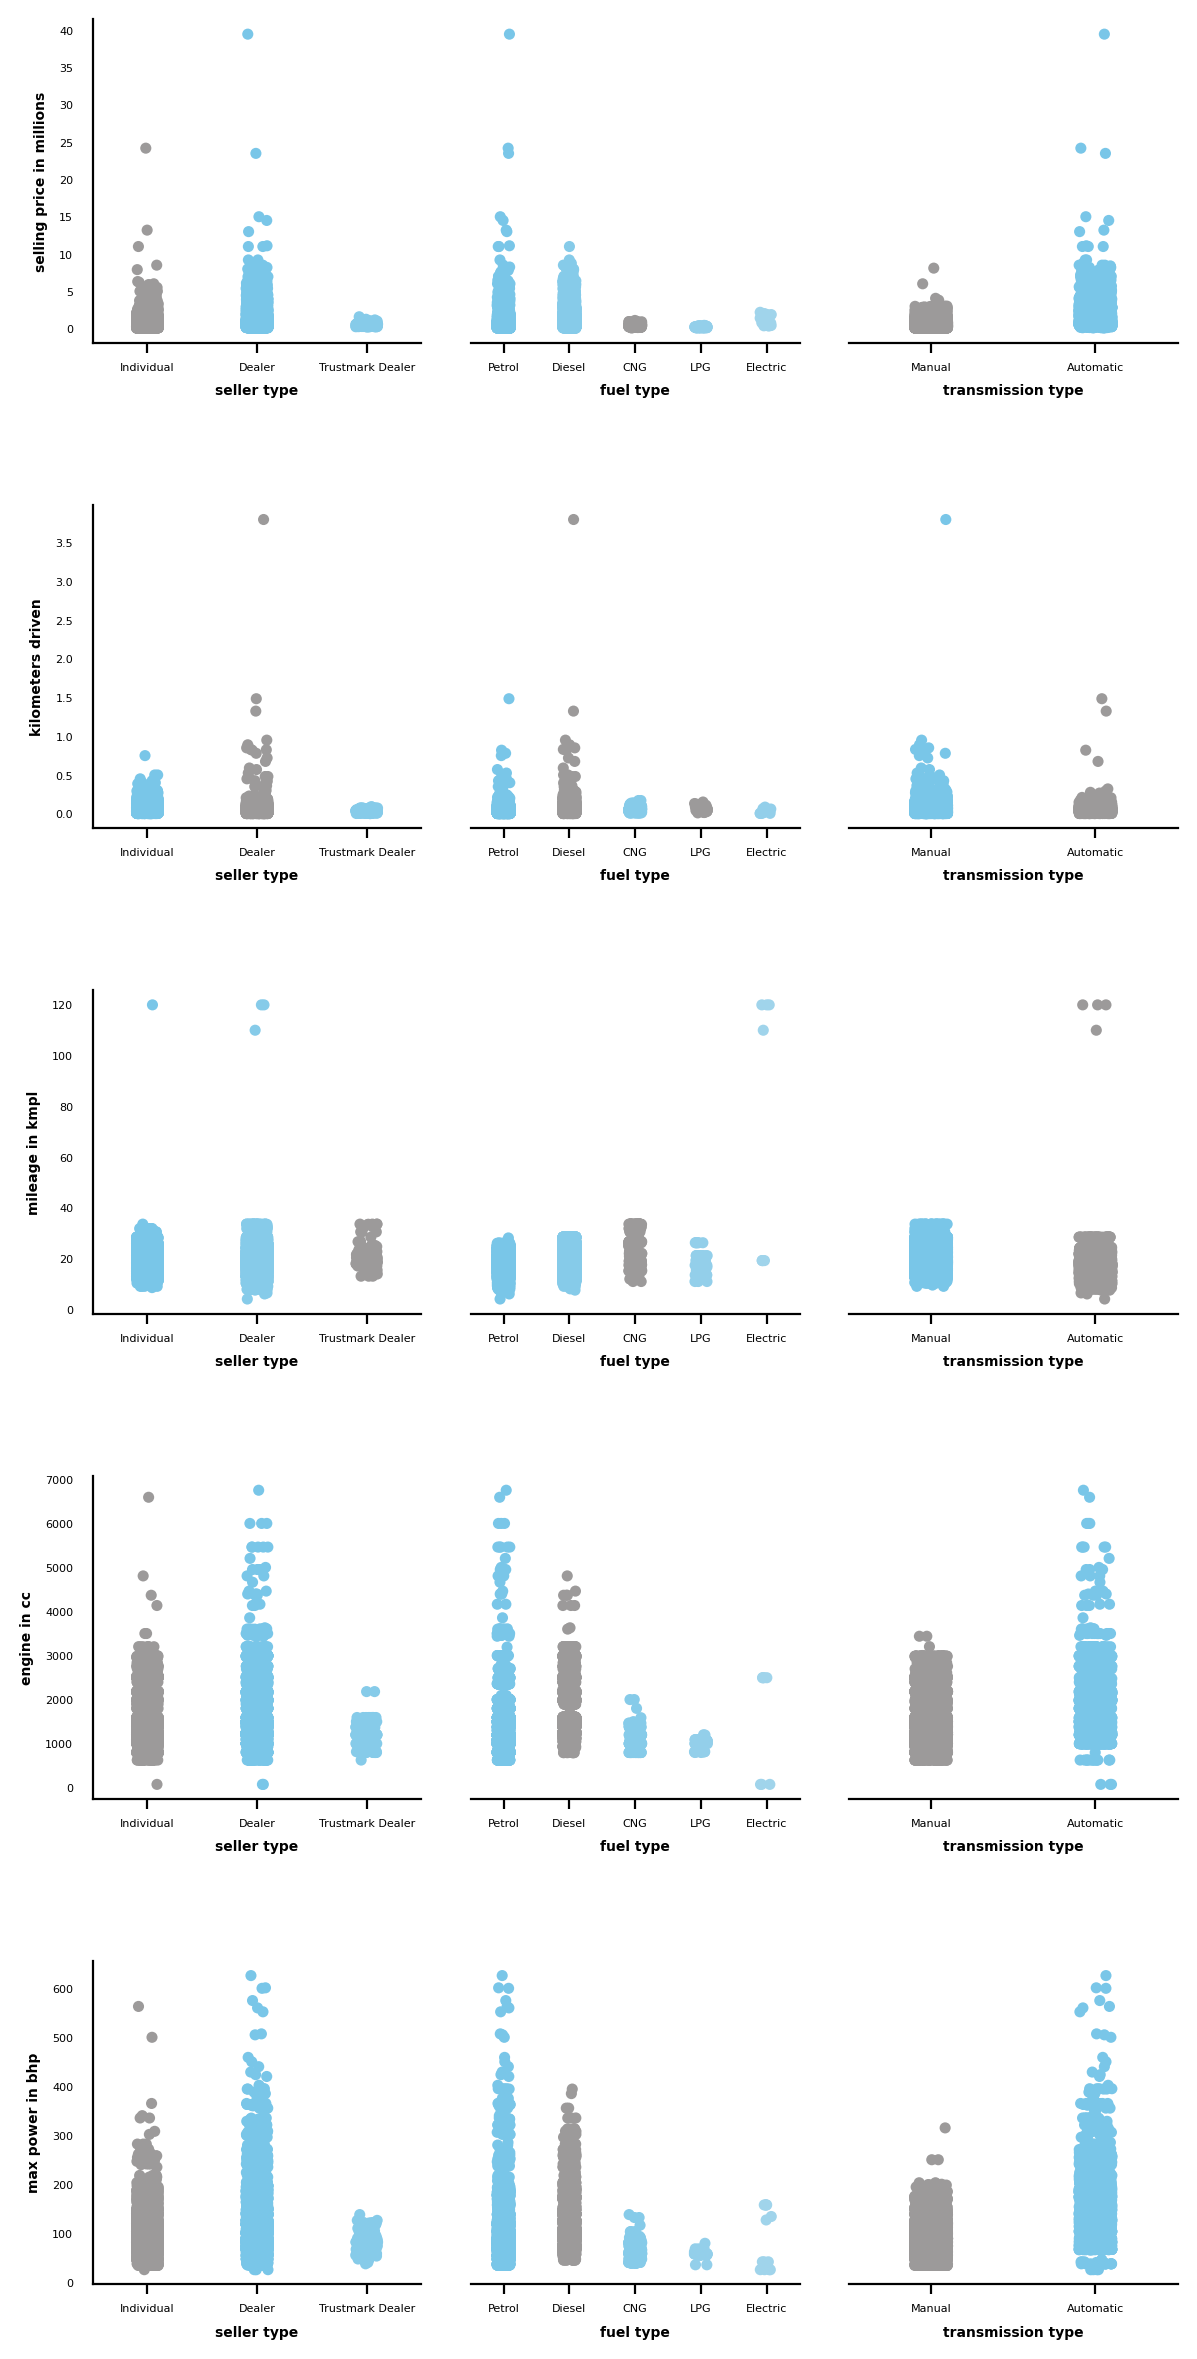

In [23]:
fig = plt.figure(figsize=(7,15))
gs = fig.add_gridspec(5,3)
gs.update(hspace=0.5, wspace=0.15)



# Row 1 selling_price-----------------------------------------------------------------
ax00 = fig.add_subplot(gs[0,0])
pal = sns.light_palette('#79c6e8', reverse=True, n_colors=10)
pal.insert(0,'#9c9a9a')
ax00_s = sns.stripplot(x=data.seller_type, y=data.selling_price/1000000, size=4, palette=pal)
ax00_s.tick_params(labelsize=4, left=False)
ax00_s.set_xlabel(xlabel='seller type', fontsize=5, weight='bold')
ax00_s.set_ylabel(ylabel='selling price in millions', fontsize=5, weight='bold')
for i in ['top', 'right']:
    ax00.spines[i].set_visible(False)

ax01 = fig.add_subplot(gs[0,1])
pal = sns.light_palette('#79c6e8', reverse=True, n_colors=10)
pal.insert(2,'#9c9a9a')
ax01_s = sns.stripplot(x=data.fuel_type, y=data.selling_price/1000000, size=4, palette=pal)
ax01_s.tick_params(labelsize=4, left=False)
ax01_s.set_xlabel(xlabel='fuel type', fontsize=5, weight='bold')
ax01_s.set_ylabel(ylabel=None)
ax01_s.set_yticks([])
for i in ['top', 'right', 'left']:
    ax01.spines[i].set_visible(False)

ax02 = fig.add_subplot(gs[0,2])
pal = sns.light_palette('#79c6e8', reverse=True, n_colors=10)
pal.insert(0,'#9c9a9a')
ax02_s = sns.stripplot(x=data.transmission_type, y=data.selling_price/1000000, size=4, palette=pal)
ax02_s.tick_params(labelsize=4, left=False)
ax02_s.set_xlabel(xlabel='transmission type', fontsize=5, weight='bold')
ax02_s.set_ylabel(ylabel=None)
ax02_s.set_yticks([])
for i in ['top', 'right', 'left']:
    ax02.spines[i].set_visible(False)

# Row 2 km_driven-------------------------------------------------------------------------
ax10 = fig.add_subplot(gs[1,0])
pal = sns.light_palette('#79c6e8', reverse=True, n_colors=10)
pal.insert(1,'#9c9a9a')
ax10_s = sns.stripplot(x=data.seller_type, y=data.km_driven/1000000, size=4, palette=pal)
ax10_s.tick_params(labelsize=4, left=False)
ax10_s.set_xlabel(xlabel='seller type', fontsize=5, weight='bold')
ax10_s.set_ylabel(ylabel='kilometers driven', fontsize=5, weight='bold')
for i in ['top', 'right']:
    ax10.spines[i].set_visible(False)

ax11 = fig.add_subplot(gs[1,1])
pal = sns.light_palette('#79c6e8', reverse=True, n_colors=10)
pal.insert(1,'#9c9a9a')
pal.insert(3,'#9c9a9a')
ax11_s = sns.stripplot(x=data.fuel_type, y=data.km_driven/1000000, size=4, palette=pal)
ax11_s.tick_params(labelsize=4, left=False)
ax11_s.set_xlabel(xlabel='fuel type', fontsize=5, weight='bold')
ax11_s.set_ylabel(ylabel=None)
ax11_s.set_yticks([])
for i in ['top', 'right', 'left']:
    ax11.spines[i].set_visible(False)

ax12 = fig.add_subplot(gs[1,2])
pal = sns.light_palette('#79c6e8', reverse=True, n_colors=10)
pal.insert(1,'#9c9a9a')
ax12_s = sns.stripplot(x=data.transmission_type, y=data.km_driven/1000000, size=4, palette=pal)
ax12_s.tick_params(labelsize=4, left=False)
ax12_s.set_xlabel(xlabel='transmission type', fontsize=5, weight='bold')
ax12_s.set_ylabel(ylabel=None)
ax12_s.set_yticks([])
for i in ['top', 'right', 'left']:
    ax12.spines[i].set_visible(False)

# Row 3 mileage---------------------------------------------------------------------------
ax20 = fig.add_subplot(gs[2,0])
pal = sns.light_palette('#79c6e8', reverse=True, n_colors=10)
pal.insert(2,'#9c9a9a')
ax20_s = sns.stripplot(x=data.seller_type, y=data.mileage, size=4, palette=pal)
ax20_s.tick_params(labelsize=4, left=False)
ax20_s.set_xlabel(xlabel='seller type', fontsize=5, weight='bold')
ax20_s.set_ylabel(ylabel='mileage in kmpl', fontsize=5, weight='bold')
for i in ['top', 'right']:
    ax20.spines[i].set_visible(False)

ax21 = fig.add_subplot(gs[2,1])
pal = sns.light_palette('#79c6e8', reverse=True, n_colors=10)
pal.insert(2,'#9c9a9a')
ax21_s = sns.stripplot(x=data.fuel_type, y=data.mileage, size=4, palette=pal)
ax21_s.tick_params(labelsize=4, left=False)
ax21_s.set_xlabel(xlabel='fuel type', fontsize=5, weight='bold')
ax21_s.set_ylabel(ylabel=None)
ax21_s.set_yticks([])
for i in ['top', 'right', 'left']:
    ax21.spines[i].set_visible(False)

ax22 = fig.add_subplot(gs[2,2])
pal = sns.light_palette('#79c6e8', reverse=True, n_colors=10)
pal.insert(1,'#9c9a9a')
ax22_s = sns.stripplot(x=data.transmission_type, y=data.mileage, size=4, palette=pal)
ax22_s.tick_params(labelsize=4, left=False)
ax22_s.set_xlabel(xlabel='transmission type', fontsize=5, weight='bold')
ax22_s.set_ylabel(ylabel=None)
ax22_s.set_yticks([])
for i in ['top', 'right', 'left']:
    ax22.spines[i].set_visible(False)

# Row 4 Engine------------------------------------------------------------------------------
ax30 = fig.add_subplot(gs[3,0])
pal = sns.light_palette('#79c6e8', reverse=True, n_colors=10)
pal.insert(0,'#9c9a9a')
ax30_s = sns.stripplot(x=data.seller_type, y=data.engine, size=4, palette=pal)
ax30_s.tick_params(labelsize=4, left=False)
ax30_s.set_xlabel(xlabel='seller type', fontsize=5, weight='bold')
ax30_s.set_ylabel(ylabel='engine in cc', fontsize=5, weight='bold')
for i in ['top', 'right']:
    ax30.spines[i].set_visible(False)

ax31 = fig.add_subplot(gs[3,1])
pal = sns.light_palette('#79c6e8', reverse=True, n_colors=10)
pal.insert(1,'#9c9a9a')
ax31_s = sns.stripplot(x=data.fuel_type, y=data.engine, size=4, palette=pal)
ax31_s.tick_params(labelsize=4, left=False)
ax31_s.set_xlabel(xlabel='fuel type', fontsize=5, weight='bold')
ax31_s.set_ylabel(ylabel=None)
ax31_s.set_yticks([])
for i in ['top', 'right', 'left']:
    ax31.spines[i].set_visible(False)

ax32 = fig.add_subplot(gs[3,2])
pal = sns.light_palette('#79c6e8', reverse=True, n_colors=10)
pal.insert(0,'#9c9a9a')
ax32_s = sns.stripplot(x=data.transmission_type, y=data.engine, size=4, palette=pal)
ax32_s.tick_params(labelsize=4, left=False)
ax32_s.set_xlabel(xlabel='transmission type', fontsize=5, weight='bold')
ax32_s.set_ylabel(ylabel=None)
ax32_s.set_yticks([])
for i in ['top', 'right', 'left']:
    ax32.spines[i].set_visible(False)

# Row 5 max power------------------------------------------------------------------------------
ax40 = fig.add_subplot(gs[4,0])
pal = sns.light_palette('#79c6e8', reverse=True, n_colors=10)
pal.insert(0,'#9c9a9a')
ax40_s = sns.stripplot(x=data.seller_type, y=data.max_power, size=4, palette=pal)
ax40_s.tick_params(labelsize=4, left=False)
ax40_s.set_xlabel(xlabel='seller type', fontsize=5, weight='bold')
ax40_s.set_ylabel(ylabel='max power in bhp', fontsize=5, weight='bold')
for i in ['top', 'right']:
    ax40.spines[i].set_visible(False)

ax41 = fig.add_subplot(gs[4,1])
pal = sns.light_palette('#79c6e8', reverse=True, n_colors=10)
pal.insert(1,'#9c9a9a')
ax41_s = sns.stripplot(x=data.fuel_type, y=data.max_power, size=4, palette=pal)
ax41_s.tick_params(labelsize=4, left=False)
ax41_s.set_xlabel(xlabel='fuel type', fontsize=5, weight='bold')
ax41_s.set_ylabel(ylabel=None)
ax41_s.set_yticks([])
for i in ['top', 'right', 'left']:
    ax41.spines[i].set_visible(False)

ax42 = fig.add_subplot(gs[4,2])
pal = sns.light_palette('#79c6e8', reverse=True, n_colors=10)
pal.insert(0,'#9c9a9a')
ax42_s = sns.stripplot(x=data.transmission_type, y=data.max_power, size=4, palette=pal)
ax42_s.tick_params(labelsize=4, left=False)
ax42_s.set_xlabel(xlabel='transmission type', fontsize=5, weight='bold')
ax42_s.set_ylabel(ylabel=None)
ax42_s.set_yticks([])
for i in ['top', 'right', 'left']:
    ax42.spines[i].set_visible(False)

plt.show()

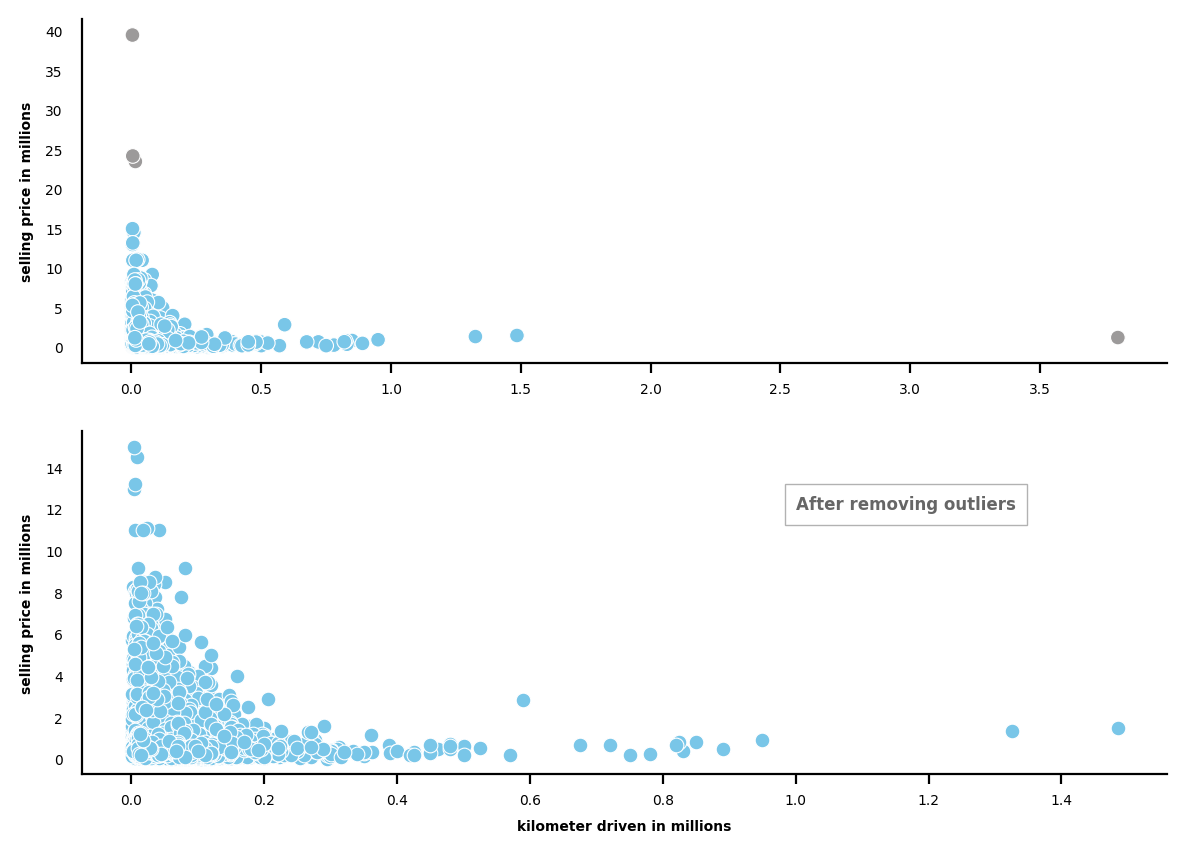

In [24]:
fig = plt.figure(figsize=(7,5))
gs = fig.add_gridspec(2,1)
color = ['#79c6e8' for i in range(data.shape[0])]
color[4967] = color[19972] = color[14257] = color[475] = '#9c9a9a'
ax=fig.add_subplot(gs[0,0])
ax.scatter(x=data.km_driven/1000000,y=data.selling_price/1000000,s=28,
                       color=color, edgecolor='white', linewidth=0.4)
ax.tick_params(labelsize=5, left=False)
ax.set_ylabel(ylabel='selling price in millions', fontsize=5, weight='bold')

ax1=fig.add_subplot(gs[1,0])
rmd_data = data[data['selling_price']<20000000]
rmd_data = rmd_data[rmd_data['km_driven']<2000000]
ax1.scatter(x=rmd_data.km_driven/1000000,y=rmd_data.selling_price/1000000,
            s=28, color='#79c6e8', edgecolor='white', linewidth=0.4)
ax1.tick_params(labelsize=5, left=False)
ax1.set_xlabel(xlabel='kilometer driven in millions', fontsize=5, weight='bold')
ax1.set_ylabel(ylabel='selling price in millions', fontsize=5, weight='bold')
ax1.text(x=1, y=12, s='After removing outliers', fontsize=6, weight='bold', alpha=0.6,
        bbox=dict(facecolor='white', lw=0.5, alpha=0.3))
sns.despine()
plt.show()

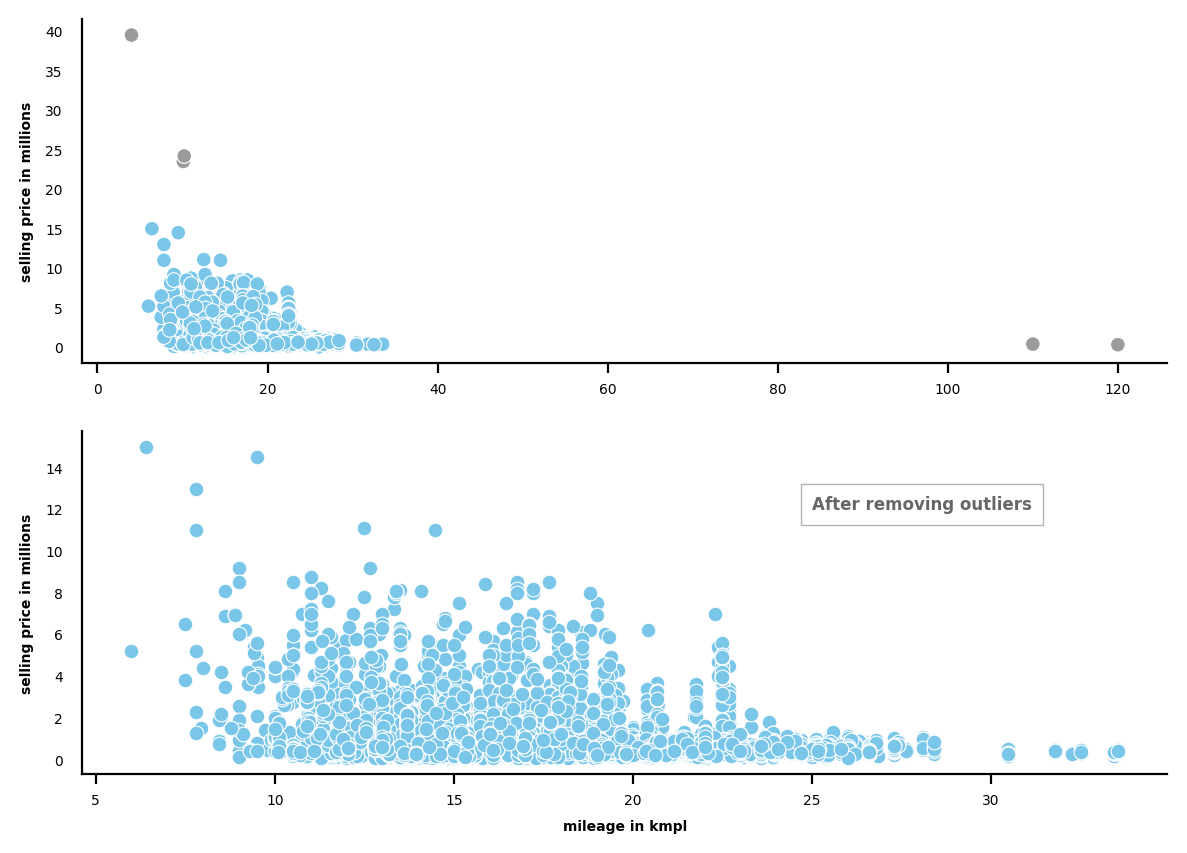

In [25]:
fig = plt.figure(figsize=(7,5))
gs = fig.add_gridspec(2,1)
color = ['#79c6e8' for i in range(data.shape[0])]
color[4967] = color[14257] = color[475] = color[11964] = color[18396]= '#9c9a9a'
ax=fig.add_subplot(gs[0,0])
ax.scatter(x=data.mileage,y=data.selling_price/1000000,s=28,
                       color=color, edgecolor='white', linewidth=0.4)
ax.tick_params(labelsize=5, left=False)
ax.set_ylabel(ylabel='selling price in millions', fontsize=5, weight='bold')

ax1=fig.add_subplot(gs[1,0])
rmd_data = data[data['selling_price']<20000000]
rmd_data = rmd_data[rmd_data['mileage']<100]
ax1.scatter(x=rmd_data.mileage,y=rmd_data.selling_price/1000000,s=28,
                       color='#79c6e8', edgecolor='white', linewidth=0.4)
ax1.tick_params(labelsize=5, left=False)
ax1.set_xlabel(xlabel='mileage in kmpl', fontsize=5, weight='bold')
ax1.set_ylabel(ylabel='selling price in millions', fontsize=5, weight='bold')
ax1.text(x=25, y=12, s='After removing outliers', fontsize=6, weight='bold', alpha=0.6,
        bbox=dict(facecolor='white', lw=0.5, alpha=0.3))
sns.despine()
plt.show()

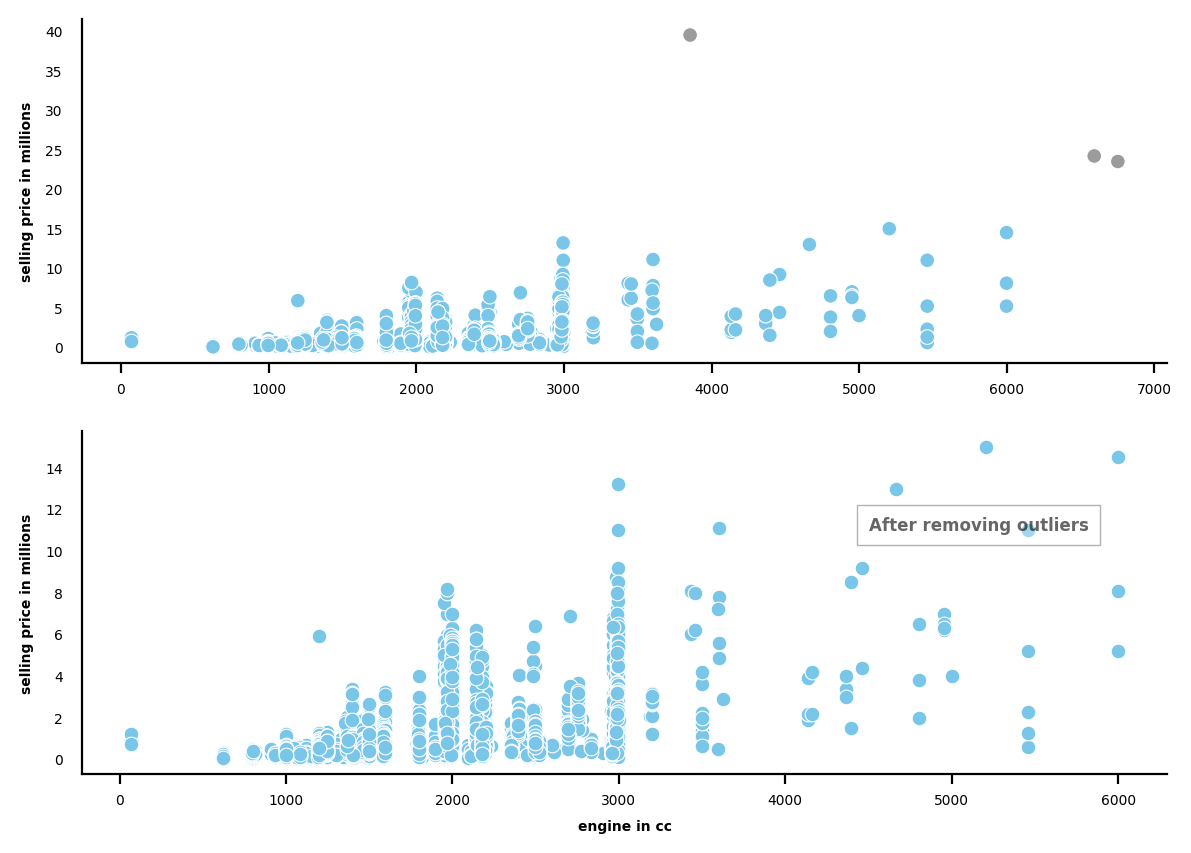

In [26]:
fig = plt.figure(figsize=(7,5))
gs = fig.add_gridspec(2,1)
color = ['#79c6e8' for i in range(data.shape[0])]
color[4967] = color[475] = color[14257] = '#9c9a9a'
ax=fig.add_subplot(gs[0,0])
ax.scatter(x=data.engine,y=data.selling_price/1000000,s=28,
                       color=color, edgecolor='white', linewidth=0.4)
ax.tick_params(labelsize=5, left=False)
ax.set_ylabel(ylabel='selling price in millions', fontsize=5, weight='bold')

ax1=fig.add_subplot(gs[1,0])
rmd_data = data[data['selling_price']<20000000]
rmd_data = rmd_data[rmd_data['engine']<6100]
ax1.scatter(x=rmd_data.engine,y=rmd_data.selling_price/1000000,s=28,
                       color='#79c6e8', edgecolor='white', linewidth=0.4)
ax1.tick_params(labelsize=5, left=False)
ax1.set_xlabel(xlabel='engine in cc', fontsize=5, weight='bold')
ax1.set_ylabel(ylabel='selling price in millions', fontsize=5, weight='bold')
ax1.text(x=4500, y=11, s='After removing outliers', fontsize=6, weight='bold', alpha=0.6,
        bbox=dict(facecolor='white', lw=0.5, alpha=0.3))
sns.despine()
plt.show()

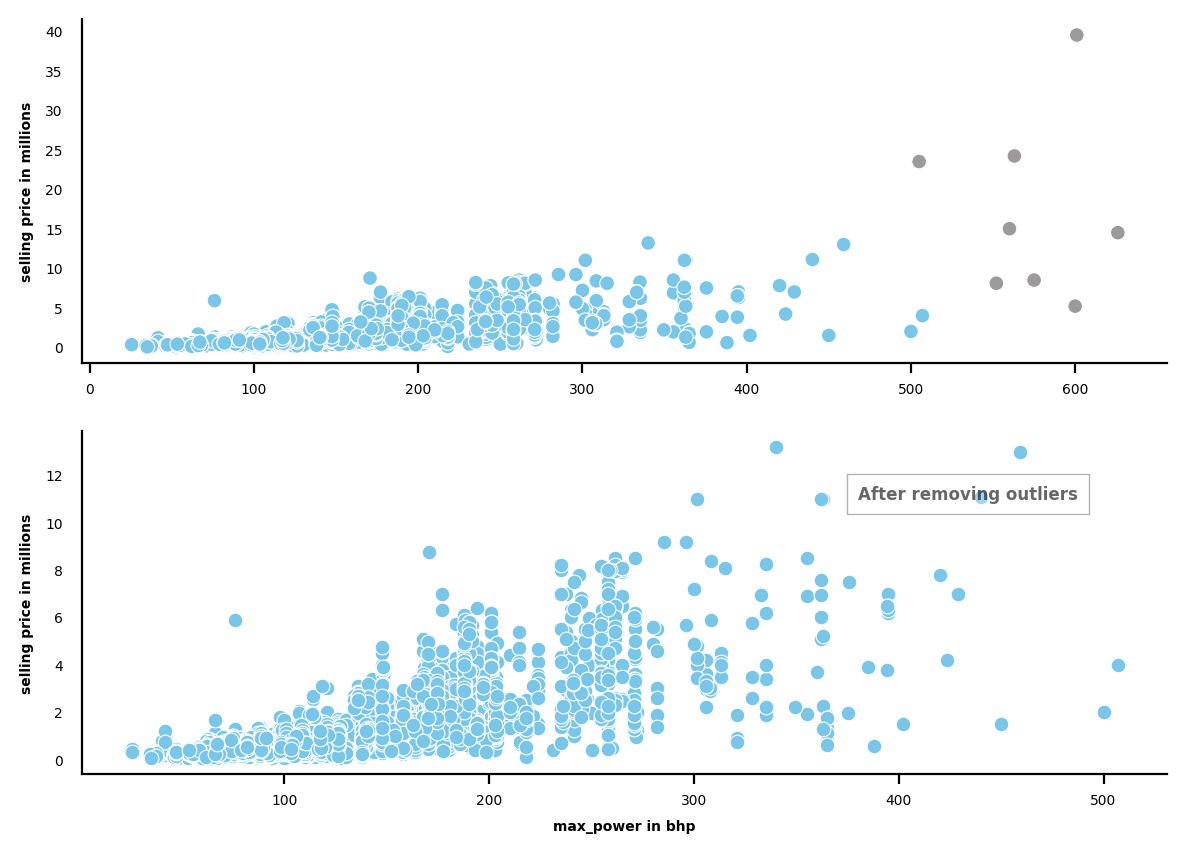

In [27]:
fig = plt.figure(figsize=(7,5))
gs = fig.add_gridspec(2,1)
color = ['#79c6e8' for i in range(data.shape[0])]
color[4967]=color[475]=color[14257]=color[1536]=color[17020]=color[16856]=color[13130]=color[3980]='#9c9a9a'
ax=fig.add_subplot(gs[0,0])
ax.scatter(x=data.max_power,y=data.selling_price/1000000,s=28,
                       color=color, edgecolor='white', linewidth=0.4)
ax.tick_params(labelsize=5, left=False)
ax.set_ylabel(ylabel='selling price in millions', fontsize=5, weight='bold')

ax1=fig.add_subplot(gs[1,0])
rmd_data = data[data['selling_price']<20000000]
rmd_data = rmd_data[rmd_data['max_power']<530]
ax1.scatter(x=rmd_data.max_power,y=rmd_data.selling_price/1000000,s=28,
                       color='#79c6e8', edgecolor='white', linewidth=0.4)
ax1.tick_params(labelsize=5, left=False)
ax1.set_xlabel(xlabel='max_power in bhp', fontsize=5, weight='bold')
ax1.set_ylabel(ylabel='selling price in millions', fontsize=5, weight='bold')
ax1.text(x=380, y=11, s='After removing outliers', fontsize=6, weight='bold', alpha=0.6,
        bbox=dict(facecolor='white', lw=0.5, alpha=0.3))
sns.despine()
plt.show()

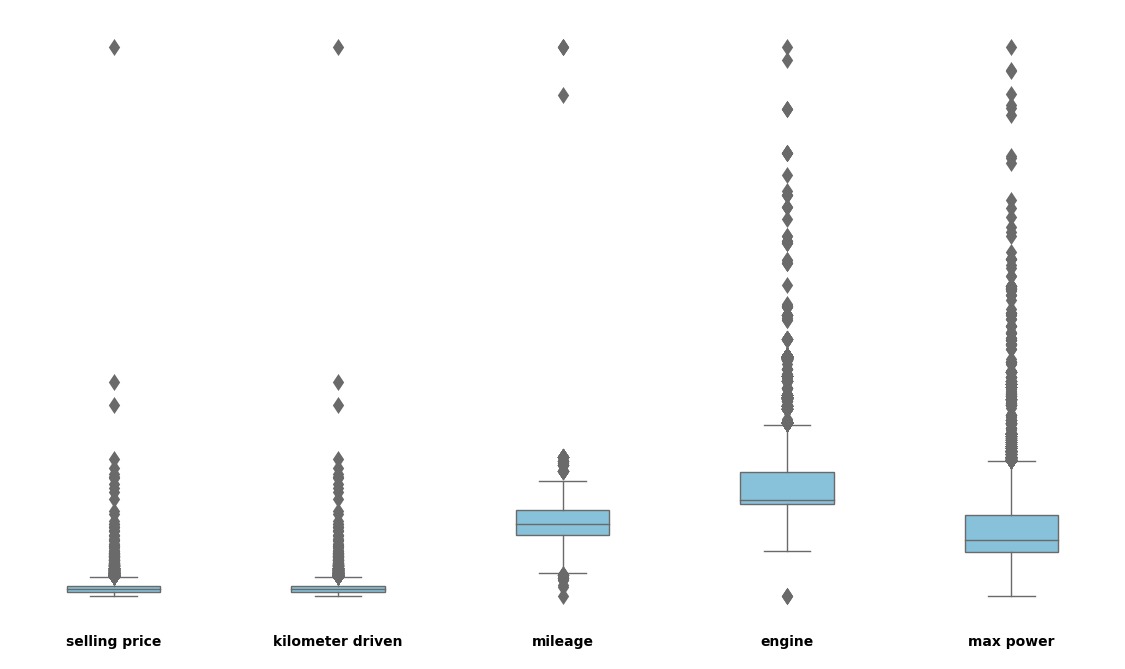

In [28]:
fig = plt.figure(figsize=(7,4))
gs = fig.add_gridspec(1,5)
gs.update(wspace=0.2)
# Selling price---------------------------
ax0=fig.add_subplot(gs[0,0])
ax0_s = sns.boxplot(y=data['km_driven'],width=0.5,color='#79c6e8',linewidth=0.5,fliersize=3)
ax0_s.tick_params(labelsize=5, left=False)
ax0_s.set_xticks([])
ax0_s.set_yticks([])
ax0_s.set_ylabel(None)
ax0_s.set_xlabel('selling price', fontsize=5, weight='bold')
for i in ['top', 'right', 'left', 'bottom']:
    ax0_s.spines[i].set_visible(False)
# Kilometer driven---------------------------
ax1=fig.add_subplot(gs[0,1])
ax1_s = sns.boxplot(y=data['km_driven'],width=0.5,color='#79c6e8',linewidth=0.5,fliersize=3)
ax1_s.tick_params(labelsize=5, left=False)
ax1_s.set_xticks([])
ax1_s.set_yticks([])
ax1_s.set_ylabel(None)
ax1_s.set_xlabel('kilometer driven', fontsize=5, weight='bold')
for i in ['top', 'right', 'left', 'bottom']:
    ax1_s.spines[i].set_visible(False)
# mileage------------------------------------
ax2=fig.add_subplot(gs[0,2])
ax2_s = sns.boxplot(y=data['mileage'],width=0.5,color='#79c6e8',linewidth=0.5,fliersize=3)
ax2_s.tick_params(labelsize=5, left=False)
ax2_s.set_xticks([])
ax2_s.set_yticks([])
ax2_s.set_ylabel(None)
ax2_s.set_xlabel('mileage', fontsize=5, weight='bold')
for i in ['top', 'right', 'left', 'bottom']:
    ax2_s.spines[i].set_visible(False)
# engine--------------------------------------
ax3=fig.add_subplot(gs[0,3])
ax3_s = sns.boxplot(y=data['engine'],width=0.5,color='#79c6e8',linewidth=0.5,fliersize=3)
ax3_s.tick_params(labelsize=5, left=False)
ax3_s.set_xticks([])
ax3_s.set_yticks([])
ax3_s.set_ylabel(None)
ax3_s.set_xlabel('engine', fontsize=5, weight='bold')
for i in ['top', 'right', 'left', 'bottom']:
    ax3.spines[i].set_visible(False)
# max power------------------------------------
ax4=fig.add_subplot(gs[0,4])
ax4_s = sns.boxplot(y=data['max_power'],width=0.5,color='#79c6e8',linewidth=0.5,fliersize=3)
ax4_s.tick_params(labelsize=5, left=False)
ax4_s.set_xticks([])
ax4_s.set_yticks([])
ax4_s.set_ylabel(None)
ax4_s.set_xlabel('max power', fontsize=5, weight='bold')
for i in ['top', 'right', 'left', 'bottom']:
    ax4_s.spines[i].set_visible(False)
    
plt.show()

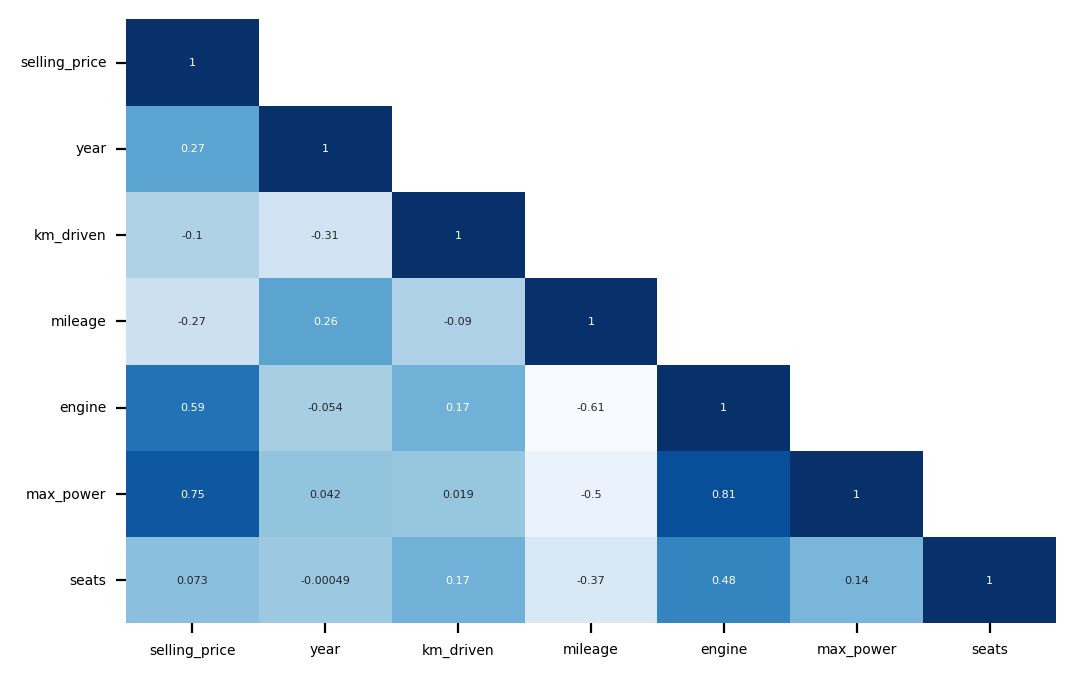

In [29]:
fig = plt.figure(figsize=(6,4))
ax = sns.heatmap(data.corr(), cmap='Blues', mask=np.triu(data.corr(), k=1), cbar=False, annot=True,
                 annot_kws=dict(fontsize=4))
ax.set_facecolor('white')
ax.tick_params(labelsize=5)
plt.show()

<div style="color:white;
           display:fill;
           border-radius:10px;
           background-color: #35bdb3;
           font-size:110%;
           font-family:Verdana;
           letter-spacing:0.5px">

<h1 style="padding: 20px; color:white; text-align:center; font-family:serif"><b>Feature engineering</b></h1>
</div>

<h3 style="font-family:serif"><b> Imputing missing values </b></h3>

In [30]:
null_count()

,features,dtypes,NaN count,NaN percentage
0,selling_price,int64,0,0.000000
1,year,int64,0,0.000000
2,seller_type,object,0,0.000000
3,km_driven,int64,0,0.000000
4,fuel_type,object,0,0.000000
5,transmission_type,object,0,0.000000
6,mileage,float64,160,0.008010
7,engine,float64,110,0.005507
8,max_power,float64,337,0.016872
9,seats,float64,87,0.004356


In [31]:
for i in ['mileage', 'engine', 'max_power', 'seats']:
    company_name = data[data[i].isnull()]['company'].value_counts().index[0]
    if data[i].nunique()>10:
        values = data[data['company']==company_name][i].mean()
    else:
        values = data[data['company']==company_name][i].median()
        
    data[i].fillna(values, inplace=True)

<h3 style="font-family:serif"><b> Removing outliers in the data </b></h3>

In [32]:
data = data[data['selling_price'] < 20000000]
data = data[data['km_driven'] < 1000000]
data = data[data['mileage'] < 100]
data = data[data['engine'] < 6100]
data = data[data['max_power'] < 530]
data = data.reset_index(drop=True)

<h3 style="font-family:serif"><b>Appling discretization on company</b></h3>

In [33]:
company_name = data.company.value_counts().index[:15]
for i in range(data.shape[0]):
    if data['company'][i] in company_name:
         continue
    else:
        data['company'][i] = 'others'

<h3 style="font-family:serif"><b>Encoding categorical features</b></h3>

In [34]:
data = pd.get_dummies(data=data, columns=['seller_type','fuel_type','transmission_type','company'], drop_first=True)
data.shape

(19959, 29)

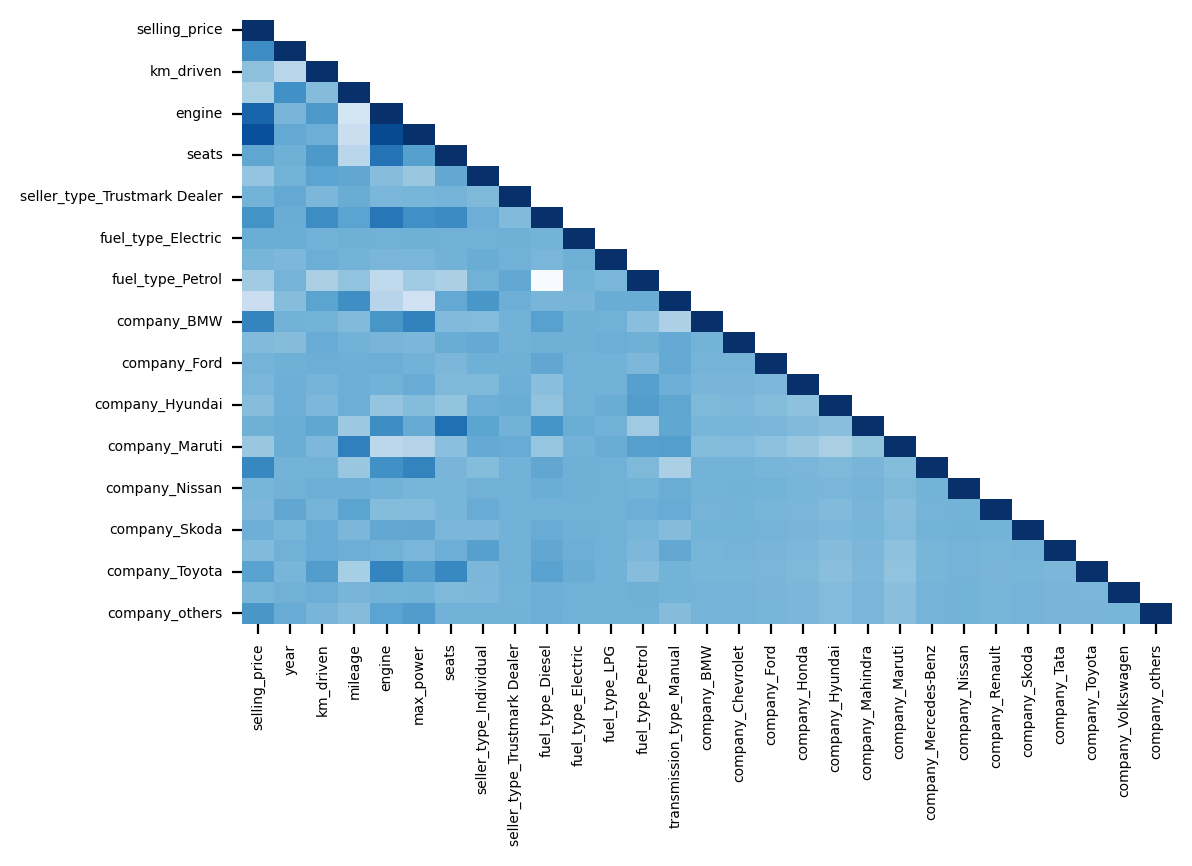

In [35]:
fig = plt.figure(figsize=(6,4))
ax = sns.heatmap(data.corr(), cmap='Blues', mask=np.triu(data.corr(), k=1), cbar=False,
                 annot_kws=dict(fontsize=4))
ax.set_facecolor('white')
ax.tick_params(labelsize=5)
plt.show()

<h3 style="font-family:serif"><b>Splitting the data into training and testing</b></h3>

In [36]:
x = data.iloc[:,1:]
y = data['selling_price']
xtrain, xtest, ytrain, ytest = train_test_split(x,y,test_size=0.20,random_state=25)

<h3 style="font-family:serif"><b>Feature Scaling</b></h3>

In [37]:
scaler = StandardScaler()
xtrain = scaler.fit_transform(xtrain)
xtest = scaler.transform(xtest)

<div style="color:white;
           display:fill;
           border-radius:10px;
           background-color: #35bdb3;
           font-size:110%;
           font-family:Verdana;
           letter-spacing:0.5px">

<h1 style="padding: 20px; color:white; text-align:center; font-family:serif"><b>Model building</b></h1>
</div>

In [38]:
def do_prediction(classifier):
    
    # training the classifier on the dataset
    classifier.fit(xtrain, ytrain)
    
    #Do prediction and evaluting the prediction
    prediction = classifier.predict(xtest)
    cross_validation_score = cross_val(xtrain, ytrain, classifier)
    error = mean_absolute_error(ytest, prediction)
    
    return error, cross_validation_score

def cross_val(xtrain, ytrain, classifier):
    
    # Applying k-Fold Cross Validation
    accuracies = cross_val_score(estimator = classifier, X = xtrain, y = ytrain, cv = 5)
    return accuracies.mean()

<h3 style="font-family:serif"><b>1. Linear Regression</b></h3>

In [39]:
model_1 = LinearRegression()
error, score = do_prediction(model_1)

print('Linear Regression MAE: {}'.format(round(error,2)))
print('Cross validation score: {}'.format(round(score,2)))

Linear Regression MAE: 235187.72
Cross validation score: 0.71


<h3 style="font-family:serif"><b>2. Decision Tree Regressor</b></h3>

In [40]:
model_2 = DecisionTreeRegressor()
error, score = do_prediction(model_2)

print('Decision Tree Regressor MAE: {}'.format(round(error,2)))
print('Cross validation score: {}'.format(round(score,2)))

Decision Tree Regressor MAE: 125909.57
Cross validation score: 0.85


<h3 style="font-family:serif"><b>3. Random Forest Regressor</b></h3>

In [41]:
model_3 = RandomForestRegressor()
error, score = do_prediction(model_3)

print('Random Forest Regressor MAE: {}'.format(round(error,2)))
print('Cross validation score: {}'.format(round(score,2)))

Random Forest Regressor MAE: 102317.21
Cross validation score: 0.92


<h3 style="font-family:serif"><b>4. Random Forest Regressor Hyperparameter tuning</b></h3>

In [42]:
best_model = RandomForestRegressor(n_estimators=400,
                                  min_samples_split=10,
                                  min_samples_leaf=1,
                                  max_features='sqrt',
                                  max_depth=60,
                                  bootstrap=False)

error, score = do_prediction(best_model)
print('Random Forest with hyperparameter tuning MAE: {}'.format(round(error,2)))
print('Cross validation score: {}'.format(round(score,2)))

Random Forest with hyperparameter tuning MAE: 99704.77
Cross validation score: 0.92
